# 13 · Image Classification with MLPs: Facial Expressions
*AI Foundations · Notebook 13 of 19*

Can a computer tell a smile from a frown? In this notebook you build a complete image-classification
pipeline in PyTorch that sorts small grayscale face images into **seven expression classes**
(angry, disgust, fear, happy, neutral, sad, surprise). The model is a plain multilayer perceptron (MLP):
it flattens each image into a long vector of pixel values and pushes it through fully connected layers.
Along the way you will learn every engineering step that real image projects need (folders → labels →
tensors → batches → training → honest evaluation), and you will discover *exactly why* MLPs are not
the end of the story for images, which sets up convolutional networks.

**What you will learn**
- How images are stored as tensors (`H×W`, `C×H×W`, `uint8` → `float32`) and how to normalize and flatten them.
- How to build label maps from folder names safely (sort!), make a stratified train/validation split, and measure class imbalance.
- How to write a PyTorch `Dataset`/`DataLoader` for images, and when to preload images into memory.
- Why upsampling 48×48 images to 128×128 cannot add information but does multiply the parameter count.
- How to train and diagnose a "pyramid" MLP, and evaluate it with a confusion matrix, per-class precision/recall, balanced accuracy and macro-F1.
- How class-weighted loss, Adam, BatchNorm, Dropout, weight decay, early stopping and augmentation change the result.
- The key structural weakness of MLPs on images (no translation invariance, blind to pixel order), shown by experiments, plus a first look at a small CNN.
- Why automatic "emotion recognition" raises serious validity and ethics questions.

**Prerequisites:** Notebooks 09–12 (softmax regression, MLPs and backpropagation, PyTorch training loops).
**Estimated time:** ~4 h.

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. The task and the data (FER-2013, how to get it, and the offline stand-in SynthFaces-7)
2. Images as tensors
3. Labels, splits and class imbalance
4. `Dataset` and `DataLoader` for images
5. The pyramid MLP baseline
6. Does a bigger image help? 48×48 versus 128×128
7. Evaluation beyond accuracy
8. Fighting class imbalance with a weighted loss
9. Making the MLP better
10. What an MLP cannot see: translations, pixel order and templates
11. Teaser: a small convolutional network
12. Is "emotion recognition" valid? Ethics and limits
13. Quiz
14. Summary and going further

## 0. Setup

The cell below imports everything, fixes the random seeds, chooses the device (a GPU if you have one,
otherwise the CPU) and defines two small helpers: `run_check` (runs the exercise checkers without
crashing the notebook) and `ensure` (installs a missing package on demand). All data lives under
`DATA_DIR = data/`.

In [1]:
import importlib
import json
import os
import random
import subprocess
import sys
import time
import urllib.request
import zipfile
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision.io import ImageReadMode, read_image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Small models gain little from many CPU threads, and too many threads fighting over busy cores can make
# training 10x slower. Use at most half of the cores (and at most 4).
torch.set_num_threads(max(1, min(4, (os.cpu_count() or 2) // 2)))
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)          # print wide tables in full in plain-text outputs
pd.set_option("display.max_columns", 20)


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


def ensure(pkg: str, import_name: str | None = None):
    """Import a package, installing it with pip first if it is missing."""
    name = import_name or pkg
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(name)


print("Python", sys.version.split()[0])
print(f"numpy {np.__version__} | pandas {pd.__version__} | torch {torch.__version__} | "
      f"torchvision {torchvision.__version__} | opencv {cv2.__version__} | matplotlib {matplotlib.__version__}")
print("device:", DEVICE, "| CPU threads used by torch:", torch.get_num_threads())

Python 3.13.15
numpy 2.5.3 | pandas 2.3.3 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | opencv 5.0.0 | matplotlib 3.11.2
device: cpu | CPU threads used by torch: 1


## 1. The task and the data

### 1.1 Facial expression recognition in one paragraph

**Facial expression recognition (FER)** means: given a picture of a face, predict which expression
it shows. The classic benchmark is **FER-2013**, released in 2013 for a machine-learning
challenge on representation learning. Its images were collected automatically: the organizers ran
web image searches with emotion-related keywords, detected the faces, cropped and roughly aligned them,
shrank them to **48×48 pixels in grayscale**, and kept the images whose label (one of seven
expression categories) passed a light human review. That collection process matters for everything that follows:

| Property | FER-2013 (approximately) | Consequence for us |
|---|---|---|
| Image size | 48×48, 1 channel (grayscale), values 0–255 | Each image is just 2,304 numbers |
| Classes | angry, disgust, fear, happy, neutral, sad, surprise | 7-way softmax classifier |
| Split sizes | ≈28.7k train / ≈7.2k test | Enough for an MLP, small for deep CNNs |
| Class balance | "happy" ≈ 25% of training data, "disgust" ≈ 1.5% | Accuracy alone will mislead us |
| Label quality | Keyword search + light review, and many ambiguous faces | Even humans agree only ≈65% of the time |
| Pose / lighting | Faces roughly centered, but pose, lighting, glasses, hands vary | Pixels of "the mouth" move around |

Rough reference points on the real FER-2013 test set: a pixel MLP like ours reaches about
**40–45%** accuracy, a small CNN about **60–70%**, carefully tuned deep CNNs about **73%**, and
the original paper estimated **human** accuracy at about **65% ± 5%**. Chance level for 7 classes is 14%,
and always answering "happy" gives about 25%.

> **Key idea.** The ceiling for this task is set by the *labels*, not only by the model. When humans
> disagree with the official label a third of the time, no model can be "99% accurate" in a meaningful way.

### 1.2 Two ways the real dataset is distributed

You will meet FER-2013 in two formats, and the notebook supports both:

```
Format A: one folder per class (popular on Kaggle)      Format B: a single CSV file (the original release)
fer2013/                                                 fer2013.csv
├── train/                                               emotion,pixels,Usage
│   ├── angry/     im0.jpg, im1.jpg, ...                 0,"70 80 82 72 58 ... (2304 numbers)",Training
│   ├── disgust/   ...                                   2,"151 150 147 155 ...",PublicTest
│   ├── ...                                              ...
│   └── surprise/
└── test/
    ├── angry/  ...                                      emotion codes: 0 Angry, 1 Disgust, 2 Fear,
    └── ...                                              3 Happy, 4 Sad, 5 Surprise, 6 Neutral
```

Notice a trap already: in the CSV, codes 4, 5 and 6 mean *sad*, *surprise* and *neutral*, but if you sort
the folder names alphabetically, indices 4, 5 and 6 are *neutral*, *sad* and *surprise*. Mixing the two
conventions silently scrambles three classes: a CSV *sad* face is read as *neutral*, a *surprise* face as
*sad*, and a *neutral* face as *surprise*. (Swapping two codes would not fix it. Only matching by name does.)
Our loader converts the CSV into the folder layout **by name**, so everything downstream uses one convention.

**To use the real data** (recommended on your own machine or in Colab), do one of these:
1. *Automatic:* create a Kaggle API token (Kaggle → Settings → "Create New Token"), make it available to
   `kagglehub` (for example as `~/.kaggle/kaggle.json`), and re-run the next cells. The code tries
   `kagglehub.dataset_download("msambare/fer2013")` (folder format).
2. *Manual:* download the dataset from Kaggle in your browser. Either put the downloaded archive at
   `data/fer2013.zip` (or keep Kaggle's name, `data/archive.zip`) and let the code unzip it, or unzip it yourself so
   that you have `data/fer2013/train/<emotion>/*.jpg` and `data/fer2013/test/<emotion>/*.jpg`. The original CSV
   release also works: put `fer2013.csv` into `data/fer2013/`.

The cell below looks for the real data in that order and reports what it found.

In [2]:
FER_DIR = DATA_DIR / "fer2013"
CSV_CODE_TO_NAME = {0: "angry", 1: "disgust", 2: "fear", 3: "happy", 4: "sad", 5: "surprise", 6: "neutral"}
IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp"}


def has_folder_layout(root: Path) -> bool:
    """True if root/train/<class>/ and root/test/<class>/ contain image files."""
    for split in ("train", "test"):
        split_dir = root / split
        if not split_dir.is_dir():
            return False
        if not any(f.suffix.lower() in IMAGE_SUFFIXES for f in split_dir.glob("*/*")):
            return False
    return True


def csv_to_folders(csv_path: Path, out_root: Path) -> None:
    """Convert the original fer2013.csv into the train/<class>/ and test/<class>/ layout (by class *name*)."""
    df = pd.read_csv(csv_path)
    for i, row in enumerate(df.itertuples(index=False)):
        split = "train" if row.Usage == "Training" else "test"   # PublicTest + PrivateTest -> test
        name = CSV_CODE_TO_NAME[int(row.emotion)]
        img = np.array(row.pixels.split(), dtype=np.uint8).reshape(48, 48)
        out_dir = out_root / split / name
        out_dir.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out_dir / f"{split}_{i:05d}.png"), img)


def try_kagglehub(dataset: str = "msambare/fer2013") -> Path | None:
    """Try to download the folder version with kagglehub and return its path or None (with a message)."""
    try:  # quick reachability test first, so offline machines do not wait or install anything
        urllib.request.urlopen("https://www.kaggle.com", timeout=5)
    except Exception as exc:
        print(f"  Kaggle is not reachable from this machine ({type(exc).__name__}), so download is skipped.")
        return None
    try:
        kagglehub = ensure("kagglehub")
        return Path(kagglehub.dataset_download(dataset))
    except Exception as exc:  # missing token, no permission, network error, ...
        print(f"  kagglehub download failed: {type(exc).__name__}: {str(exc)[:120]}")
        return None


def locate_real_fer() -> Path | None:
    """Return a root folder with train/ and test/ class folders for real FER-2013, or None."""
    if has_folder_layout(FER_DIR):
        return FER_DIR
    for zip_path in (DATA_DIR / "fer2013.zip", DATA_DIR / "archive.zip"):
        if zip_path.exists():
            print(f"  extracting {zip_path} ...")
            with zipfile.ZipFile(zip_path) as zf:
                zf.extractall(FER_DIR)
            for candidate in (FER_DIR, *sorted(FER_DIR.iterdir())):   # the archive may contain one extra folder level
                if candidate.is_dir() and has_folder_layout(candidate):
                    return candidate
    for csv_path in (FER_DIR / "fer2013.csv", DATA_DIR / "fer2013.csv"):
        if csv_path.exists():
            print(f"  converting {csv_path} into class folders ...")
            csv_to_folders(csv_path, FER_DIR)
            return FER_DIR
    downloaded = try_kagglehub()
    if downloaded is not None and has_folder_layout(downloaded):
        return downloaded
    return None


print("Looking for the real FER-2013 ...")
REAL_ROOT = locate_real_fer()
print("Real FER-2013 found at:", REAL_ROOT if REAL_ROOT else "nowhere (we will use the offline stand-in)")

Looking for the real FER-2013 ...


  Kaggle is not reachable from this machine (URLError); skipping download.
Real FER-2013 found at: nowhere (we will use the offline stand-in)


### 1.3 The offline stand-in: SynthFaces-7

The machine that executed this notebook cannot reach Kaggle, so it generates an **offline stand-in**
called *SynthFaces-7*. It is designed so that the *identical* pipeline runs on it:

* same layout: 48×48 grayscale image files (PNG here. The Kaggle folder version uses JPEG, and the loader
  reads both) in `train/<emotion>/` and `test/<emotion>/` folders,
* same seven class names and the **same class proportions as FER-2013** (including the tiny
  "disgust" class), at one third of the size so that everything runs in minutes on a laptop CPU,
* deliberately **hard**: the expression signal is often weak and the faces vary in many ways that have
  nothing to do with the expression.

Each cartoon face is drawn from a small *generative model* with three ingredients:

1. **Expression parameters (the signal).** Nine numbers describe the face in a simplified "muscle"
   language: eyebrow raise, eyebrow tilt, eye openness, mouth curvature (smile or frown), mouth opening,
   mouth width, mouth asymmetry, and the chance of nose wrinkles or visible teeth. Each class has a
   *prototype* (table below). A face of class $k$ gets
   $\boldsymbol\theta = \boldsymbol\theta_{\text{neutral}} + t\,(\boldsymbol\theta_k - \boldsymbol\theta_{\text{neutral}}) + \text{jitter}$,
   where the **intensity** $t \in [0.15, 1]$ is random. Small $t$ means a subtle expression that looks almost neutral,
   exactly the kind of face real annotators argue about.
2. **Nuisance factors (the noise).** Position (up to ±4 px), size, in-plane rotation, a fake head turn,
   face shape, skin tone, hair, background clutter, line thickness, blur, uneven lighting, contrast,
   sensor noise, and occluders (a "hand" blob or sunglasses) on some faces.
3. **Label noise.** About 8% of labels are replaced by a *confusable* class (fear ↔ surprise,
   sad ↔ neutral, angry ↔ disgust, ...), imitating annotator disagreement.

> **Intuition.** A good stand-in dataset keeps the *structure* of the real problem (format, imbalance,
> ambiguity, nuisance variation) even if the pictures look different. Then the lessons you learn on
> it (what helps, what fails, why) transfer to the real thing.

In [3]:
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]   # alphabetical = folder order
FER_TRAIN_COUNTS = np.array([3995, 436, 4097, 7215, 4965, 4830, 3171])  # real FER-2013, folder version
FER_TEST_COUNTS = np.array([958, 111, 1024, 1774, 1233, 1247, 831])
SYNTH_SCALE = 1 / 3          # SynthFaces-7 keeps FER's class proportions at one third of its size

PROTOTYPES = pd.DataFrame(   # how each expression moves the face, with "neutral" as the reference point
    [[-0.08, -0.15, 0.40, -0.05, 0.03, 0.27, 0.00, 0.3, 0.5],   # angry: brows down and inward, narrowed eyes
     [-0.05, -0.08, 0.30, -0.06, 0.05, 0.30, 0.14, 1.0, 0.3],   # disgust: nose wrinkles, one-sided mouth
     [0.09, 0.10, 0.95, -0.05, 0.14, 0.37, 0.00, 0.0, 0.6],     # fear: inner brows up, wide eyes, stretched mouth
     [0.03, 0.00, 0.33, 0.17, 0.11, 0.42, 0.00, 0.0, 0.7],      # happy: corners up, wide mouth, squinting eyes
     [0.00, 0.00, 0.55, 0.00, 0.00, 0.30, 0.00, 0.0, 0.0],      # neutral
     [0.02, 0.13, 0.40, -0.13, 0.00, 0.28, 0.00, 0.0, 0.0],     # sad: inner brows up, corners down
     [0.15, 0.00, 1.00, 0.00, 0.30, 0.19, 0.00, 0.0, 0.2]],     # surprise: brows high, eyes wide, round open mouth
    index=EMOTIONS,
    columns=["brow_raise", "brow_tilt", "eye_open", "mouth_curve", "mouth_open", "mouth_width",
             "mouth_asym", "p_wrinkle", "p_teeth"])
JITTER_SD = np.array([0.03, 0.045, 0.12, 0.045, 0.03, 0.04, 0.03, 0.0, 0.0])  # per-face randomness
CONFUSABLE = {"angry": ["disgust", "sad", "neutral"], "disgust": ["angry", "sad"], "fear": ["surprise", "sad"],
              "happy": ["neutral", "surprise"], "neutral": ["sad", "angry"], "sad": ["neutral", "fear"],
              "surprise": ["fear", "happy"]}
display(PROTOTYPES)


def sample_face_params(labels: np.ndarray, rng: np.random.Generator) -> dict:
    """Sample expression + nuisance parameters for faces with the given class indices."""
    n = len(labels)
    proto = PROTOTYPES.to_numpy()[labels]
    neutral = PROTOTYPES.loc["neutral"].to_numpy()
    t = 0.15 + 0.85 * rng.beta(2.0, 1.6, n)                       # expression intensity in [0.15, 1]
    expr = neutral + t[:, None] * (proto - neutral) + rng.normal(size=(n, 9)) * JITTER_SD
    p = {name: expr[:, j] for j, name in enumerate(PROTOTYPES.columns)}
    p["eye_open"] = np.clip(p["eye_open"], 0.12, 1.15)
    p["mouth_open"] = np.clip(p["mouth_open"], 0, None)
    p["mouth_width"] = np.clip(p["mouth_width"], 0.15, 0.5)
    p["mouth_asym"] = p["mouth_asym"] * rng.choice([-1.0, 1.0], n)   # left or right side
    p["wrinkle"] = rng.random(n) < p["p_wrinkle"] * t
    p["teeth"] = rng.random(n) < p["p_teeth"]
    p["t"] = t
    # ---- nuisance factors (nothing to do with the expression) ----
    p["cx"] = 24 + np.clip(rng.normal(0, 1.6, n), -4, 4)          # face center in 48x48 pixel units
    p["cy"] = 25 + np.clip(rng.normal(0, 1.6, n), -4, 4)
    p["half_w"] = rng.uniform(16, 21, n)                           # half face width (pixels)
    p["aspect"] = rng.uniform(1.15, 1.38, n)                       # face height / width
    p["rot"] = np.clip(rng.normal(0, 6, n), -15, 15)               # in-plane rotation (degrees)
    p["yaw"] = np.clip(rng.normal(0, 0.06, n), -0.14, 0.14)        # fake head turn
    p["eye_dx"], p["eye_y"] = rng.uniform(0.32, 0.42, n), rng.uniform(-0.26, -0.14, n)
    p["mouth_y"] = rng.uniform(0.40, 0.55, n)
    p["skin"], p["bg"], p["ink"] = rng.uniform(95, 215, n), rng.uniform(0, 255, n), rng.uniform(10, 70, n)
    p["stroke"] = rng.uniform(0.9, 1.6, n)
    p["hair"] = rng.random(n) < 0.7
    p["hair_tone"] = np.where(rng.random(n) < 0.75, rng.uniform(10, 70, n), rng.uniform(150, 230, n))
    p["hairline"] = rng.uniform(-0.75, -0.5, n)
    p["clutter"] = rng.integers(0, 4, n)                           # background blobs
    p["occlude"] = rng.random(n)                                   # < 0.12: hand blob, < 0.18: sunglasses
    return p

,brow_raise,brow_tilt,eye_open,mouth_curve,mouth_open,mouth_width,mouth_asym,p_wrinkle,p_teeth
angry,-0.08,-0.15,0.40,-0.05,0.03,0.27,0.00,0.3,0.5
disgust,-0.05,-0.08,0.30,-0.06,0.05,0.30,0.14,1.0,0.3
fear,0.09,0.10,0.95,-0.05,0.14,0.37,0.00,0.0,0.6
happy,0.03,0.00,0.33,0.17,0.11,0.42,0.00,0.0,0.7
neutral,0.00,0.00,0.55,0.00,0.00,0.30,0.00,0.0,0.0
sad,0.02,0.13,0.40,-0.13,0.00,0.28,0.00,0.0,0.0
surprise,0.15,0.00,1.00,0.00,0.30,0.19,0.00,0.0,0.2


The drawing code works in **face coordinates**: $x$ runs from $-1$ (left edge of the face) to $+1$
(right edge) and $y$ points *down* (eyes near $y \approx -0.2$, mouth near $y \approx 0.5$). The helper
`to_px` scales, rotates and translates these coordinates into canvas pixels. We draw on a 96×96 canvas
(twice the final size) with anti-aliased OpenCV primitives in sub-pixel precision, then average 2×2
blocks down to 48×48, which gives smooth edges like a real downsized photo. You do not need to study
every line of the drawing code, just skim it to see which parameter controls which part of the face.

In [4]:
CANVAS, SUB = 96, 16          # canvas size, OpenCV sub-pixel factor (coordinates in 1/16 pixel, shift=4)
AA, SHIFT = cv2.LINE_AA, 4


def to_px(p: dict, i: int, x, y) -> np.ndarray:
    """Face coordinates -> fixed-point canvas coordinates for face i (shape (..., 2))."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    x = x + p["yaw"][i] * (1 - 0.3 * np.abs(y))                   # features slide sideways on a turned head
    xs, ys = x * p["half_w"][i], y * p["half_w"][i] * p["aspect"][i] * 0.95
    th = np.deg2rad(p["rot"][i])
    X = p["cx"][i] + xs * np.cos(th) - ys * np.sin(th)
    Y = p["cy"][i] + xs * np.sin(th) + ys * np.cos(th)
    return np.stack([X, Y], -1) * (CANVAS / 48) * SUB


def ipt(a) -> tuple:
    """Round a 2-vector to an integer tuple for OpenCV."""
    return tuple(int(v) for v in a)


def draw_head_and_hair(img, p, i, rng):
    for _ in range(p["clutter"][i]):                               # random background shapes
        c, ax = rng.integers(0, CANVAS, 2) * SUB, rng.integers(4, CANVAS // 2, 2) * SUB
        cv2.ellipse(img, ipt(c), ipt(ax), float(rng.uniform(0, 180)), 0, 360, float(rng.uniform(0, 255)), -1, AA, SHIFT)
    hw, asp, rot, s = p["half_w"][i], p["aspect"][i], p["rot"][i], CANVAS / 48 * SUB
    axes = (int(hw * s), int(hw * asp * 0.95 * s))
    if p["hair"][i]:                                               # hair mass behind the head
        cv2.ellipse(img, ipt(to_px(p, i, 0.0, -0.25)), (int(axes[0] * 1.12), int(axes[1] * 0.95)), rot, 0, 360,
                    float(p["hair_tone"][i]), -1, AA, SHIFT)
    cv2.ellipse(img, ipt(to_px(p, i, 0.0, 0.0)), axes, rot, 0, 360, float(p["skin"][i]), -1, AA, SHIFT)
    if p["hair"][i]:                                               # fringe covering the forehead
        xs = np.linspace(-1.0, 1.0, 9)
        top = np.stack([xs, -np.sqrt(np.clip(1 - xs ** 2, 0, 1)) * 1.05], -1)
        line = np.stack([xs[::-1], p["hairline"][i] + 0.12 * xs[::-1] ** 2], -1)
        poly = to_px(p, i, *np.concatenate([top, line]).T).astype(np.int32)
        cv2.fillPoly(img, [poly], float(p["hair_tone"][i]), AA, SHIFT)


def thick(p, i, k):
    """Line thickness in canvas pixels for face i (k = relative weight)."""
    return max(1, int(round(k * p["stroke"][i] * CANVAS / 48)))


def draw_eyes_and_brows(img, p, i):
    ink, skin, hw, rot = float(p["ink"][i]), float(p["skin"][i]), p["half_w"][i], p["rot"][i]
    ey, ex, s = p["eye_y"][i], p["eye_dx"][i], CANVAS / 48 * SUB
    for side in (-1, 1):
        c = ipt(to_px(p, i, side * ex, ey))
        a = (int(0.15 * hw * s), max(SUB, int(0.15 * hw * p["eye_open"][i] * 0.9 * s)))
        if p["eye_open"][i] < 0.28:                                # nearly closed eye: just a curved line
            cv2.ellipse(img, c, (a[0], max(SUB, a[0] // 3)), rot, 200, 340, ink, thick(p, i, 1.0), AA, SHIFT)
        else:                                                      # white of the eye, outline, pupil
            cv2.ellipse(img, c, a, rot, 0, 360, min(255.0, skin + 45), -1, AA, SHIFT)
            cv2.ellipse(img, c, a, rot, 0, 360, ink, thick(p, i, 0.6), AA, SHIFT)
            cv2.circle(img, c, max(SUB, int(min(a[0] * 0.55, a[1] * 0.9))), ink, -1, AA, SHIFT)
        xs = np.linspace(0.12, 0.55, 6)                            # eyebrow from inner (u=0) to outer (u=1) end
        u = (xs - 0.12) / 0.43
        by = ey - 0.24 - p["brow_raise"][i]
        ys = by - p["brow_tilt"][i] * (0.5 - u) - (0.03 + 0.3 * max(p["brow_raise"][i], 0)) * np.sin(np.pi * u)
        cv2.polylines(img, [to_px(p, i, side * xs, ys).astype(np.int32)], False, ink, thick(p, i, 1.3), AA, SHIFT)

In [5]:
def draw_nose_and_mouth(img, p, i):
    ink, skin, ey = float(p["ink"][i]), float(p["skin"][i]), p["eye_y"][i]
    nose = to_px(p, i, [0.0, -0.05, 0.08], [ey + 0.1, 0.18, 0.2]).astype(np.int32)
    cv2.polylines(img, [nose], False, 0.5 * ink + 0.5 * skin, thick(p, i, 0.7), AA, SHIFT)
    if p["wrinkle"][i]:                                            # wrinkles beside the nose bridge
        for side in (-1, 1):
            w = to_px(p, i, [side * 0.08, side * 0.2], [ey + 0.12, ey + 0.2]).astype(np.int32)
            cv2.polylines(img, [w], False, ink, thick(p, i, 0.7), AA, SHIFT)
    w, my, o = p["mouth_width"][i], p["mouth_y"][i], p["mouth_open"][i]
    xs = np.linspace(-w, w, 13)
    u = xs / w                                                     # -1 (left corner) ... +1 (right corner)
    mid = my - p["mouth_curve"][i] * u ** 2 - p["mouth_asym"][i] * u   # curve > 0 lifts the corners: a smile
    if o < 0.035:                                                  # closed mouth: a single curved line
        cv2.polylines(img, [to_px(p, i, xs, mid).astype(np.int32)], False, ink, thick(p, i, 1.1), AA, SHIFT)
        return
    upper = mid - 0.25 * o * (1 - u ** 2)
    lower = mid + o * np.sqrt(np.clip(1 - u ** 2, 0, 1))
    poly = to_px(p, i, np.concatenate([xs, xs[::-1]]), np.concatenate([upper, lower[::-1]])).astype(np.int32)
    cv2.fillPoly(img, [poly], 0.6 * ink, AA, SHIFT)                # dark open mouth
    if p["teeth"][i]:
        band = upper + np.minimum(0.07, 0.45 * o) * np.sqrt(np.clip(1 - u ** 2, 0, 1))
        teeth = to_px(p, i, np.concatenate([xs, xs[::-1]]), np.concatenate([upper, band[::-1]])).astype(np.int32)
        cv2.fillPoly(img, [teeth], min(255.0, skin + 50), AA, SHIFT)
    cv2.polylines(img, [poly], True, ink, thick(p, i, 0.8), AA, SHIFT)


def draw_occluder(img, p, i, rng):
    s, occ = CANVAS / 48 * SUB, p["occlude"][i]
    if occ < 0.12:                                                 # a "hand" or object in front of the face
        c = to_px(p, i, rng.uniform(-0.8, 0.8), rng.uniform(-0.6, 0.9))
        cv2.ellipse(img, ipt(c), ipt(rng.uniform(5, 14, 2) * s), float(rng.uniform(0, 180)), 0, 360,
                    float(rng.uniform(0, 255)), -1, AA, SHIFT)
    elif occ < 0.18:                                               # sunglasses hide the eyes
        hw, ey, ex = p["half_w"][i], p["eye_y"][i], p["eye_dx"][i]
        for side in (-1, 1):
            cv2.ellipse(img, ipt(to_px(p, i, side * ex, ey)), (int(0.2 * hw * s), int(0.13 * hw * s)),
                        p["rot"][i], 0, 360, float(rng.uniform(5, 40)), -1, AA, SHIFT)
        bridge = to_px(p, i, [-ex + 0.2, ex - 0.2], [ey, ey]).astype(np.int32)
        cv2.polylines(img, [bridge], False, 20.0, thick(p, i, 0.8), AA, SHIFT)


def draw_face(p: dict, i: int, rng: np.random.Generator) -> np.ndarray:
    """Draw face i on a CANVAS x CANVAS uint8 image."""
    img = np.full((CANVAS, CANVAS), p["bg"][i], np.uint8)
    draw_head_and_hair(img, p, i, rng)
    draw_eyes_and_brows(img, p, i)
    draw_nose_and_mouth(img, p, i)
    draw_occluder(img, p, i, rng)
    return img

Finally, we "photograph" the drawings: average 2×2 blocks (96 → 48 pixels), blur half of the images
slightly, add a random lighting gradient, change contrast and brightness, add sensor noise, and round
back to integers in 0–255. Then we corrupt about 8% of the labels with a confusable class.

In [6]:
def finish_images(canvases: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Downsample 96->48 and add photographic nuisances. Returns uint8 array (n, 48, 48)."""
    n = len(canvases)
    x = canvases.reshape(n, 48, 2, 48, 2).astype(np.float32).mean(axis=(2, 4))   # 2x2 block average
    for i in np.flatnonzero(rng.random(n) < 0.5):
        x[i] = cv2.GaussianBlur(x[i], (0, 0), float(rng.uniform(0.4, 1.0)))
    yy, xx = np.mgrid[-1:1:48j, -1:1:48j]
    phi = rng.uniform(0, 2 * np.pi, n)[:, None, None]
    gain = rng.uniform(0, 0.35, n)[:, None, None]
    x = x * (1 + gain * (np.cos(phi) * xx + np.sin(phi) * yy))          # light coming from one side
    m = x.mean(axis=(1, 2), keepdims=True)
    x = (x - m) * rng.uniform(0.55, 1.15, n)[:, None, None] + m + rng.uniform(-25, 25, n)[:, None, None]
    x = x + rng.normal(0, 1, x.shape) * rng.uniform(1, 10, n)[:, None, None]   # sensor noise
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)


def swap_some_labels(labels: np.ndarray, rng: np.random.Generator, p_swap: float = 0.08) -> np.ndarray:
    """Replace a fraction p_swap of labels by a confusable class (imitates annotator disagreement)."""
    out = labels.copy()
    for i in np.flatnonzero(rng.random(len(labels)) < p_swap):
        out[i] = EMOTIONS.index(rng.choice(CONFUSABLE[EMOTIONS[labels[i]]]))
    return out


def make_synthfaces(counts: np.ndarray, seed: int):
    """Generate sum(counts) faces. Returns (images uint8 (n,48,48), noisy labels, clean labels, params)."""
    g = np.random.default_rng(seed)
    clean = np.repeat(np.arange(len(EMOTIONS)), counts)
    g.shuffle(clean)
    p = sample_face_params(clean, g)
    canvases = np.stack([draw_face(p, i, g) for i in range(len(clean))])
    return finish_images(canvases, g), swap_some_labels(clean, g), clean, p

Now we write the faces to disk in exactly the FER folder layout. Generation takes about half a minute on a
laptop (longer on a busy machine), and a small `meta.json` file lets later runs skip it (delete the folder to regenerate).

In [7]:
SYNTH_DIR = DATA_DIR / "synthfaces7"
SYNTH_VERSION = "synthfaces7-v2"


def write_image_folder(split_dir: Path, images: np.ndarray, labels: np.ndarray) -> None:
    """Save images as split_dir/<emotion>/<split>_<index>.png."""
    for name in EMOTIONS:
        (split_dir / name).mkdir(parents=True, exist_ok=True)
    for i, (img, k) in enumerate(zip(images, labels)):
        cv2.imwrite(str(split_dir / EMOTIONS[k] / f"{split_dir.name}_{i:05d}.png"), img)


def build_synthfaces7(root: Path = SYNTH_DIR) -> Path:
    """Create SynthFaces-7 under root (train/ and test/), unless an identical version already exists."""
    train_counts = np.round(FER_TRAIN_COUNTS * SYNTH_SCALE).astype(int)
    test_counts = np.round(FER_TEST_COUNTS * SYNTH_SCALE).astype(int)
    meta = {"version": SYNTH_VERSION, "train": train_counts.tolist(), "test": test_counts.tolist()}
    meta_file = root / "meta.json"
    if meta_file.exists() and json.loads(meta_file.read_text()) == meta and has_folder_layout(root):
        print(f"SynthFaces-7 already on disk at {root}. Reusing it.")
        return root
    t0 = time.time()
    for split, counts, seed in (("train", train_counts, 1), ("test", test_counts, 2)):
        images, labels, clean, _ = make_synthfaces(counts, seed)
        write_image_folder(root / split, images, labels)
        print(f"  {split}: {len(images):,} faces, {np.mean(labels != clean):.1%} labels swapped")
    meta_file.write_text(json.dumps(meta))
    print(f"SynthFaces-7 written to {root} in {time.time() - t0:.1f} s")
    return root


if REAL_ROOT is not None:
    DATASET_NAME, DATASET_ROOT = "FER-2013 (real)", REAL_ROOT
else:
    DATASET_NAME, DATASET_ROOT = "SynthFaces-7 (offline stand-in)", build_synthfaces7()
print(f"\n>>> All results below were produced with: {DATASET_NAME}  [{DATASET_ROOT}]")

  train: 9,570 faces, 7.6% labels swapped


  test: 2,392 faces, 8.4% labels swapped
SynthFaces-7 written to data/synthfaces7 in 11.7 s

>>> All results below were produced with: SynthFaces-7 (offline stand-in)  [data/synthfaces7]


## 2. Images as tensors

### 2.1 A grayscale image is a matrix of small integers

A digital grayscale image is a grid of **pixels**, and each pixel stores one brightness value. The usual
storage type is `uint8` (unsigned 8-bit integer), so values run from $0$ (black) to $255$ (white).
A 48×48 face is therefore a matrix $I \in \{0, 1, \dots, 255\}^{48 \times 48}$: row index $r$ goes
*down*, column index $c$ goes *right*, and $I[r, c]$ is the brightness at that spot.

Different libraries order the axes differently, and mixing them up is one of the most common bugs:

| Library | Shape of one image | Shape of a batch |
|---|---|---|
| NumPy / OpenCV / matplotlib / Pillow | `H × W` (gray) or `H × W × C` (color) | no fixed convention |
| PyTorch / torchvision | `C × H × W` (channels first, gray: `1 × H × W`) | `N × C × H × W` |

Here $H$ = height (rows), $W$ = width (columns), $C$ = channels (1 for gray, 3 for RGB) and
$N$ = batch size. Let us open one file both ways.

In [8]:
def list_class_dirs(split_dir: Path) -> list[str]:
    """Class folder names inside split_dir, sorted alphabetically (more on sorting in Section 3)."""
    return sorted(d.name for d in split_dir.iterdir() if d.is_dir())


example_path = sorted((DATASET_ROOT / "train" / "happy").iterdir())[0]
img_np = cv2.imread(str(example_path), cv2.IMREAD_GRAYSCALE)        # NumPy array, H x W
img_t = read_image(str(example_path), mode=ImageReadMode.GRAY)      # torch tensor, C x H x W
print("file:", example_path.name)
print(f"OpenCV  -> type {type(img_np).__name__}, shape {img_np.shape}, dtype {img_np.dtype}")
print(f"torch   -> type {type(img_t).__name__}, shape {tuple(img_t.shape)}, dtype {img_t.dtype}")
print("same pixels?", np.array_equal(img_np, img_t[0].numpy()), "| min", img_np.min(), "max", img_np.max())
print("top-left 5x8 corner of the matrix:\n", img_np[:5, :8])

file: train_00002.png
OpenCV  -> type ndarray, shape (48, 48), dtype uint8
torch   -> type Tensor, shape (1, 48, 48), dtype torch.uint8
same pixels? True | min 16 max 120
top-left 5x8 corner of the matrix:
 [[26 32 28 28 32 28 32 25]
 [31 25 27 26 31 32 30 30]
 [32 32 31 33 21 27 33 27]
 [30 36 32 28 25 25 30 28]
 [30 25 32 31 29 27 24 27]]


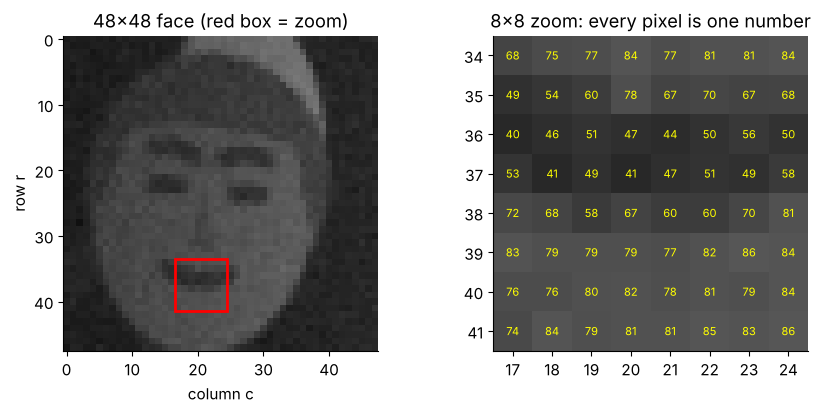

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].imshow(img_np, cmap="gray", vmin=0, vmax=255)
r0, c0 = 34, 17                                                    # top-left corner of the zoom window
axes[0].add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), 8, 8, fill=False, ec="red", lw=2))
axes[0].set_title("48×48 face (red box = zoom)")
axes[0].set_xlabel("column c"); axes[0].set_ylabel("row r")
crop = img_np[r0:r0 + 8, c0:c0 + 8]
axes[1].imshow(crop, cmap="gray", vmin=0, vmax=255)
for (r, c), v in np.ndenumerate(crop):
    axes[1].text(c, r, str(v), ha="center", va="center", fontsize=8, color="red" if v > 127 else "yellow")
axes[1].set_title("8×8 zoom: every pixel is one number")
axes[1].set_xticks(range(8), labels=range(c0, c0 + 8)); axes[1].set_yticks(range(8), labels=range(r0, r0 + 8))
axes[1].grid(False); axes[0].grid(False)
plt.tight_layout(); plt.show()

### 2.2 From `uint8` to `float32`, and why we normalize

Neural networks need **floating-point** inputs: gradients are fractional numbers, and integer
arithmetic misbehaves. A classic trap is `uint8` overflow: the arithmetic wraps around modulo 256.

In [10]:
a = np.array([200, 250], dtype=np.uint8)
b = np.array([100, 10], dtype=np.uint8)
print("uint8 :", a, "+", b, "=", a + b, "   <- wrapped around modulo 256!")
print("float :", a.astype(np.float32) + b.astype(np.float32))
print("mean of uint8 tensor needs a float dtype:", torch.tensor([200, 250], dtype=torch.uint8).float().mean().item())

uint8 : [200 250] + [100  10] = [44  4]    <- wrapped around modulo 256!
float : [300. 260.]
mean of uint8 tensor needs a float dtype: 225.0


After converting to `float32` we **rescale** the values. Four common choices for an input pixel $x \in [0, 255]$:

| Name | Formula | Range | Comment |
|---|---|---|---|
| unit range | $x / 255$ | $[0, 1]$ | simplest, all inputs positive |
| symmetric range | $x / 127.5 - 1$ | $[-1, 1]$ | centered around 0, used in this notebook |
| dataset standardization | $(x/255 - \mu) / \sigma$ | mean 0, std 1 over the training set | $\mu, \sigma$ computed on the **training** split only |
| per-image standardization | $(x - \bar{x}_{\text{img}}) / s_{\text{img}}$ | each image: mean 0, std 1 | removes brightness and contrast differences |

Worked example for four pixel values (check one by hand: $64/127.5 - 1 = 0.502 - 1 = -0.498$):

| $x$ | $x/255$ | $x/127.5-1$ |
|---|---|---|
| 0 | 0.000 | −1.000 |
| 64 | 0.251 | −0.498 |
| 128 | 0.502 | 0.004 |
| 255 | 1.000 | 1.000 |

**Why bother?** A first-layer neuron computes $z = \mathbf{w}^\top\mathbf{x} + b$, a sum of 2,304 terms. With raw
values up to 255, the pre-activations $z$ at initialization are hundreds of times larger than with inputs in $[-1, 1]$
(Section 9.2 measures this), the logits become huge, the softmax saturates, and a learning rate that suits one
input scale is far too large or too small for another. Centering also helps gradient descent: the gradient for the
weights of one neuron is $\partial \mathcal{L}/\partial \mathbf{w} = \delta \cdot \mathbf{x}$, where $\delta$ is a single
number. If every $x_j > 0$, all 2,304 weight updates of that neuron share the sign of $\delta$ for this example,
so the weights can only move "all up" or "all down" together, which leads to zig-zag progress.
Zero-centered inputs remove that constraint. (In Section 9 you will see the effect in an experiment.)

> **Common pitfall.** Computing $\mu$ and $\sigma$ on the whole dataset (train + test) leaks test
> information into training. Always fit normalization statistics on the training split only.

In [11]:
x = torch.tensor([0, 64, 128, 255], dtype=torch.uint8)
xf = x.to(torch.float32)
print("x / 255        :", (xf / 255).numpy().round(3))
print("x / 127.5 - 1  :", (xf / 127.5 - 1).numpy().round(3))
face = img_t.float()
per_image = (face - face.mean()) / face.std()
print(f"per-image standardization of the example face: mean {per_image.mean():.3f}, std {per_image.std():.3f}")

x / 255        : [0.    0.251 0.502 1.   ]
x / 127.5 - 1  : [-1.    -0.498  0.004  1.   ]
per-image standardization of the example face: mean 0.000, std 1.000


### 2.3 Flattening: what the MLP actually sees

An MLP's first layer is `nn.Linear(in_features, out_features)`: it expects each example to be a
**vector**. So we *flatten* the $1 \times 48 \times 48$ tensor into a vector of $48 \cdot 48 = 2304$ numbers.
PyTorch and NumPy flatten in **row-major order**: first all of row 0, then all of row 1, and so on, so
pixel $(r, c)$ lands at position $j = r \cdot W + c$. For a tiny 3×3 image:

```
 image (3x3)          flattened (9,)
 [[a, b, c],          [a, b, c, d, e, f, g, h, i]
  [d, e, f],   --->    0  1  2  3  4  5  6  7  8      pixel (r=1, c=2) = f  ->  j = 1*3 + 2 = 5
  [g, h, i]]
```

`nn.Flatten()` (default `start_dim=1`) flattens everything **except the batch dimension**:
`(N, 1, 48, 48) → (N, 2304)`.

> **Common pitfall.** `x.view(-1)` or `x.flatten()` on a batch merges the batch dimension too and
> produces one giant vector of length $N \cdot 2304$. Use `nn.Flatten()` or `x.flatten(start_dim=1)`.

tiny image:
 tensor([[0, 1, 2],
        [3, 4, 5],
        [6, 7, 8]])
nn.Flatten() -> tensor([[0, 1, 2, 3, 4, 5, 6, 7, 8]]) shape (1, 9)
batch (32, 1, 48, 48) -> nn.Flatten: (32, 2304) | wrong x.view(-1): (73728,)


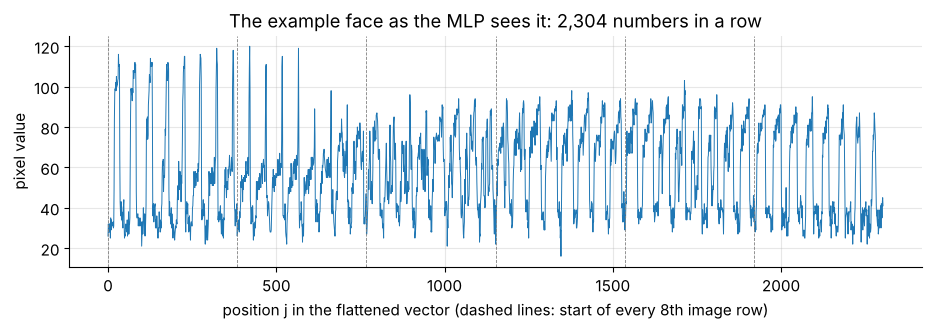

In [12]:
tiny = torch.arange(9).reshape(1, 1, 3, 3)                # a batch with one 1x3x3 "image"
print("tiny image:\n", tiny[0, 0])
print("nn.Flatten() ->", nn.Flatten()(tiny), "shape", tuple(nn.Flatten()(tiny).shape))
batch = torch.zeros(32, 1, 48, 48)
print("batch", tuple(batch.shape), "-> nn.Flatten:", tuple(nn.Flatten()(batch).shape),
      "| wrong x.view(-1):", tuple(batch.view(-1).shape))

flat = img_t.float().flatten()
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(flat.numpy(), lw=0.7)
for r in range(0, 2304, 48 * 8):
    ax.axvline(r, color="gray", lw=0.6, ls="--")
ax.set_xlabel("position j in the flattened vector (dashed lines: start of every 8th image row)")
ax.set_ylabel("pixel value"); ax.set_title("The example face as the MLP sees it: 2,304 numbers in a row")
plt.show()

Look at the plot: the 2D picture has become a 1D signal with a rough period of 48 (one image row).
Two pixels that are vertical neighbors in the face (positions $j$ and $j+48$) are far apart in this
vector. The MLP is never told which inputs are neighbors, so it must *learn* any spatial relationship
from data. Keep this in mind: it is the root of the MLP's weaknesses in Section 10.

**Quick check.** A color image batch has shape `(64, 3, 32, 32)`. What is the shape after
`nn.Flatten()`, and where does the green value of pixel (row 2, column 5) land?

<details>
<summary>Answer</summary>

`(64, 3072)` because $3 \cdot 32 \cdot 32 = 3072$. Flattening is row-major over `(C, H, W)`, so the index is
$c \cdot (32 \cdot 32) + r \cdot 32 + \text{col} = 1 \cdot 1024 + 2 \cdot 32 + 5 = 1093$ (green is channel 1).
</details>

### ✏️ Exercise 1: from `uint8` image to model input

Write `to_model_input(img)` that takes a `uint8` tensor of shape `(1, H, W)` (as returned by
`read_image`) and returns a `float32` tensor of the same shape scaled to $[-1, 1]$ with
$x \mapsto x/127.5 - 1$. Do not modify the input in place.

In [13]:
# ✏️ Exercise 1: from uint8 image to model input
def to_model_input(img: torch.Tensor) -> torch.Tensor:
    """uint8 (1, H, W) in [0, 255] -> float32 (1, H, W) in [-1, 1]."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex1():
    img = torch.tensor([[[0, 51, 255], [127, 128, 200]]], dtype=torch.uint8)
    out = to_model_input(img)
    assert out.dtype == torch.float32, f"dtype should be float32, got {out.dtype}"
    assert out.shape == img.shape, f"shape should stay {tuple(img.shape)}, got {tuple(out.shape)}"
    expected = torch.tensor([[[-1.0, -0.6, 1.0], [-0.003922, 0.003922, 0.568627]]])
    assert torch.allclose(out, expected, atol=1e-5), f"got {out}"
    assert img.dtype == torch.uint8 and img[0, 0, 2] == 255, "the input must not be modified"


run_check("Exercise 1", _test_ex1)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def to_model_input(img):
    return img.to(torch.float32) / 127.5 - 1.0
```
Converting to `float32` *first* matters: `img / 127.5` on a `uint8` tensor would also promote to float in
PyTorch, but `img - 1` on `uint8` would wrap around (0 − 1 = 255). Being explicit about the dtype avoids both traps.
</details>

## 3. Labels, splits and class imbalance

### 3.1 From folder names to integer labels, and why you must sort

In the folder layout, the **label of an image is the name of its parent folder**. A network needs
integers $0, \dots, K-1$ (here $K = 7$), so we build two dictionaries:
`label2idx` (name → index, used when loading) and `idx2label` (index → name, used when reporting).

The tempting one-liner `os.listdir(train_dir)` returns names in whatever order the **file system**
stores them. That order differs between operating systems, file systems, and even between two copies of
the same folder. If the training run and the evaluation run build their mappings from different
orders, "happy" might be class 3 during training and class 5 during testing: the model is fine, but
every report is garbage, and nothing crashes. Sorting makes the mapping a deterministic function of the names.

In [14]:
train_dir, test_dir = DATASET_ROOT / "train", DATASET_ROOT / "test"
print("os.listdir order on this machine:", os.listdir(train_dir))

classes = list_class_dirs(train_dir)                      # sorted -> deterministic
label2idx = {name: i for i, name in enumerate(classes)}
idx2label = {i: name for name, i in label2idx.items()}
assert list_class_dirs(test_dir) == classes, "train and test must have the same class folders"
NUM_CLASSES = len(classes)
print("label2idx:", label2idx)

# What could go wrong: simulate a second machine that lists the folders in a different order.
other_order = [str(c) for c in np.random.default_rng(7).permutation(classes)]
bad_map = {name: i for i, name in enumerate(other_order)}
print("unsorted mapping on 'another machine':", bad_map)
print("classes whose index silently changed:", [c for c in classes if bad_map[c] != label2idx[c]])

os.listdir order on this machine: ['happy', 'sad', 'neutral', 'angry', 'fear', 'surprise', 'disgust']
label2idx: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
unsorted mapping on 'another machine': {'angry': 0, 'sad': 1, 'surprise': 2, 'fear': 3, 'neutral': 4, 'disgust': 5, 'happy': 6}
classes whose index silently changed: ['disgust', 'fear', 'happy', 'sad', 'surprise']


### 3.2 Listing the image files

Next we collect every image path together with its integer label. We sort the paths too, so the
list (and therefore the random split below) is identical on every machine.

In [15]:
def read_img_files(split_dir: Path, label2idx: dict) -> tuple[list[Path], np.ndarray]:
    """Return (sorted list of image paths, integer labels) for split_dir/<class>/<image files>."""
    paths, labels = [], []
    for name, idx in label2idx.items():
        files = sorted(f for f in (split_dir / name).iterdir() if f.suffix.lower() in IMAGE_SUFFIXES)
        paths += files
        labels += [idx] * len(files)
    return paths, np.array(labels, dtype=np.int64)


train_paths, train_labels = read_img_files(train_dir, label2idx)
test_paths, test_labels = read_img_files(test_dir, label2idx)
print(f"train files: {len(train_paths):,} | test files: {len(test_paths):,}")
print("first train file:", train_paths[0].relative_to(DATASET_ROOT), "-> label", train_labels[0])

train files: 9,570 | test files: 2,392
first train file: train/angry/train_00009.png -> label 0


### 3.3 How imbalanced is the data?

Count the images per class. The table also lists the real FER-2013 proportions for comparison.
SynthFaces-7 was built to match them.

,train,train %,test,test %,FER-2013 train %
angry,1306,13.65,318,13.29,13.92
disgust,159,1.66,37,1.55,1.52
fear,1347,14.08,347,14.51,14.27
happy,2279,23.81,549,22.95,25.13
neutral,1713,17.90,428,17.89,17.29
sad,1650,17.24,416,17.39,16.82
surprise,1116,11.66,297,12.42,11.05


imbalance ratio (largest / smallest class): 14.3
'always predict happy' would score 23.0% test accuracy; random guessing scores about 14.3%


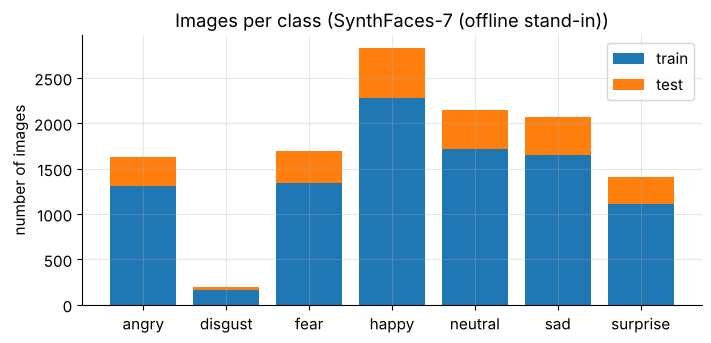

In [16]:
counts_tr = np.bincount(train_labels, minlength=NUM_CLASSES)
counts_te = np.bincount(test_labels, minlength=NUM_CLASSES)
balance = pd.DataFrame({"train": counts_tr, "train %": 100 * counts_tr / counts_tr.sum(),
                        "test": counts_te, "test %": 100 * counts_te / counts_te.sum(),
                        "FER-2013 train %": 100 * FER_TRAIN_COUNTS / FER_TRAIN_COUNTS.sum()},
                       index=classes).round(2)
display(balance)
majority = classes[int(counts_te.argmax())]
print(f"imbalance ratio (largest / smallest class): {counts_tr.max() / counts_tr.min():.1f}")
print(f"'always predict {majority}' would score {counts_te.max() / counts_te.sum():.1%} test accuracy, and "
      f"random guessing scores about {1 / NUM_CLASSES:.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(classes, counts_tr, color="tab:blue", label="train")
ax.bar(classes, counts_te, bottom=counts_tr, color="tab:orange", label="test")
ax.set_ylabel("number of images"); ax.set_title(f"Images per class ({DATASET_NAME})"); ax.legend()
plt.show()

In SynthFaces-7 the largest class is about 14 times larger than the smallest one (in the real FER-2013 it is
16.5 times, and the stand-in's label swaps move a few faces between classes). Two consequences that will
follow us through the notebook:

1. **Accuracy is dominated by big classes.** A model can ignore "disgust" completely and lose less than
   2 percentage points of accuracy. We will therefore also report *balanced accuracy* and *macro-F1* (Section 7).
2. **Small classes are fragile in splits.** With only a hundred-odd "disgust" training images in SynthFaces-7
   (436 in the real FER-2013 training folder), a careless split can leave very few of them for validation.

### 3.4 A stratified train/validation split

We never tune anything on the test set. Instead we carve a **validation set** (20%) out of the
training folder and use it for every decision (learning rate, number of epochs, architecture). The test
set is touched only to report final numbers.

A **stratified** split samples the validation set *separately inside each class*, so every class keeps
(up to rounding) the same proportion in both parts. The experiment below repeats a plain random split
and a stratified split with 100 different seeds and counts the "disgust" images that land in validation.

'disgust' images in validation over 100 seeds: plain random 21–49 (std 5.3) | stratified 32–32 (std 0.0)


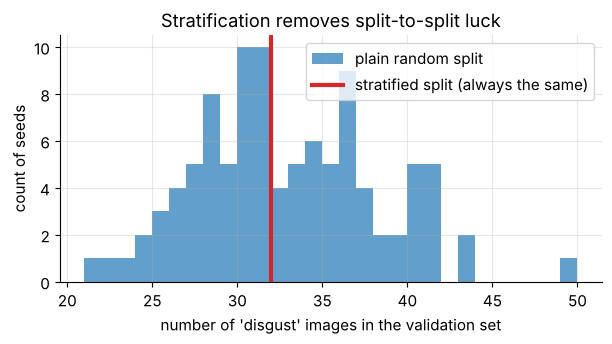

In [17]:
from sklearn.model_selection import train_test_split

all_idx = np.arange(len(train_paths))
disgust = label2idx["disgust"]
plain, strat = [], []
for s in range(100):
    _, v_plain = train_test_split(all_idx, test_size=0.2, random_state=s)
    _, v_strat = train_test_split(all_idx, test_size=0.2, random_state=s, stratify=train_labels)
    plain.append(np.sum(train_labels[v_plain] == disgust))
    strat.append(np.sum(train_labels[v_strat] == disgust))
print(f"'disgust' images in validation over 100 seeds: plain random {min(plain)}–{max(plain)} "
      f"(std {np.std(plain):.1f}) | stratified {min(strat)}–{max(strat)} (std {np.std(strat):.1f})")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(plain, bins=range(min(plain), max(plain) + 2), alpha=0.7, label="plain random split")
ax.axvline(np.mean(strat), color="tab:red", lw=3, label="stratified split (always the same)")
ax.set_xlabel("number of 'disgust' images in the validation set"); ax.set_ylabel("count of seeds")
ax.set_title("Stratification removes split-to-split luck"); ax.legend(); plt.show()

Now the split we will actually use for the rest of the notebook:

In [18]:
tr_idx, va_idx = train_test_split(all_idx, test_size=0.2, random_state=SEED, stratify=train_labels)
y_tr, y_va, y_te = train_labels[tr_idx], train_labels[va_idx], test_labels
split_table = pd.DataFrame({"train": np.bincount(y_tr, minlength=NUM_CLASSES),
                            "val": np.bincount(y_va, minlength=NUM_CLASSES),
                            "test": np.bincount(y_te, minlength=NUM_CLASSES)}, index=classes)
split_table.loc["total"] = split_table.sum()
split_table["val share"] = (split_table["val"] / (split_table["train"] + split_table["val"])).round(3)
display(split_table)

,train,val,test,val share
angry,1045,261,318,0.200
disgust,127,32,37,0.201
fear,1078,269,347,0.200
happy,1823,456,549,0.200
neutral,1370,343,428,0.200
sad,1320,330,416,0.200
surprise,893,223,297,0.200
total,7656,1914,2392,0.200


> **Olympiad tip.** "Stratify by the label" is the default answer whenever classes are imbalanced and
> the dataset is small. If there are *groups* (several photos of the same person), you must also keep
> each group entirely on one side of the split (sklearn's `GroupShuffleSplit` / `StratifiedGroupKFold`),
> otherwise the model can recognize the person instead of the expression and the validation score is inflated.

### ✏️ Exercise 2: safe label maps

Write `build_label_maps(folder_names)` returning `(label2idx, idx2label)`. It must ignore the input
order (sort the names), ignore duplicates, and the two dictionaries must be inverses of each other.

In [19]:
# ✏️ Exercise 2: safe label maps
def build_label_maps(folder_names: list[str]) -> tuple[dict, dict]:
    """Return (label2idx, idx2label) built from the *sorted* unique folder names."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex2():
    l2i, i2l = build_label_maps(["sad", "happy", "angry", "surprise", "happy"])
    assert l2i == {"angry": 0, "happy": 1, "sad": 2, "surprise": 3}, f"label2idx wrong: {l2i}"
    assert i2l == {0: "angry", 1: "happy", 2: "sad", 3: "surprise"}, f"idx2label wrong: {i2l}"
    l2i_b, _ = build_label_maps(["surprise", "sad", "angry", "happy"])
    assert l2i_b == l2i, "the mapping must not depend on the input order"


run_check("Exercise 2", _test_ex2)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def build_label_maps(folder_names):
    names = sorted(set(folder_names))
    label2idx = {name: i for i, name in enumerate(names)}
    idx2label = {i: name for i, name in enumerate(names)}
    return label2idx, idx2label
```
`set` removes duplicates and `sorted` fixes the order, so the result depends only on *which* names exist.
</details>

### ✏️ Exercise 3: a stratified split from scratch

Implement `stratified_split(labels, val_frac, seed)` without scikit-learn. For each class $k$ with
$n_k$ examples, put $\operatorname{round}(n_k \cdot \text{val\_frac})$ randomly chosen examples into validation and
the rest into training. Return two sorted index arrays `(train_idx, val_idx)`.

In [20]:
# ✏️ Exercise 3: a stratified split from scratch
def stratified_split(labels: np.ndarray, val_frac: float, seed: int) -> tuple[np.ndarray, np.ndarray]:
    """Return sorted (train_idx, val_idx) with each class split in proportion val_frac."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex3():
    labels = np.array([0] * 50 + [1] * 7 + [2] * 23)
    tr, va = stratified_split(labels, 0.2, seed=0)
    assert len(np.intersect1d(tr, va)) == 0, "train and val must not overlap"
    assert np.array_equal(np.sort(np.concatenate([tr, va])), np.arange(len(labels))), "every index used once"
    assert list(np.bincount(labels[va], minlength=3)) == [10, 1, 5], f"val counts {np.bincount(labels[va])}"
    tr2, va2 = stratified_split(labels, 0.2, seed=0)
    assert np.array_equal(va, va2), "same seed must give the same split"
    assert np.all(np.diff(va) > 0) and np.all(np.diff(tr) > 0), "return sorted index arrays"


run_check("Exercise 3", _test_ex3)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def stratified_split(labels, val_frac, seed):
    g = np.random.default_rng(seed)
    val = []
    for k in np.unique(labels):
        idx = np.flatnonzero(labels == k)
        n_val = int(round(len(idx) * val_frac))
        val.extend(g.choice(idx, size=n_val, replace=False))
    val = np.sort(np.array(val, dtype=int))
    train = np.setdiff1d(np.arange(len(labels)), val)   # setdiff1d returns sorted values
    return train, val
```
With 7 examples of class 1, $7 \cdot 0.2 = 1.4$ rounds to 1 validation example, and that rounding is why
stratified splits keep proportions only "up to one example per class".
</details>

## 4. `Dataset` and `DataLoader` for images

PyTorch separates two jobs:

* a **`Dataset`** answers two questions: "how many examples are there?" (`__len__`) and "give me
  example number `i`" (`__getitem__`, returning one `(image, label)` pair),
* a **`DataLoader`** wraps a `Dataset` and serves **mini-batches**: it shuffles the indices each epoch,
  collects `batch_size` examples, and stacks them into tensors of shape `(N, 1, 48, 48)` and `(N,)`.

### 4.1 The textbook version: read each file on demand

The class below reads the PNG from disk *every time* an example is requested ("lazy loading"),
optionally resizes it, and converts it to `float32` in $[-1, 1]$.

In [21]:
from torchvision.transforms.functional import resize as tv_resize


class FaceFolderDataset(Dataset):
    """Lazy dataset: reads, (optionally) resizes and normalizes one image file per __getitem__."""

    def __init__(self, paths: list[Path], labels: np.ndarray, size: int | None = None):
        self.paths = list(paths)
        self.labels = torch.as_tensor(labels, dtype=torch.long)
        self.size = size

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int):
        img = read_image(str(self.paths[i]), mode=ImageReadMode.GRAY)          # uint8 (1, H, W)
        if self.size is not None and tuple(img.shape[-2:]) != (self.size, self.size):
            img = tv_resize(img, [self.size, self.size], antialias=True)
        x = img.to(torch.float32) / 127.5 - 1.0                                # float32 in [-1, 1]
        return x, self.labels[i]


lazy_train = FaceFolderDataset([train_paths[i] for i in tr_idx], y_tr)
x0, y0 = lazy_train[0]
print(f"len = {len(lazy_train):,}. One example: x {tuple(x0.shape)} {x0.dtype} in [{x0.min():.2f}, {x0.max():.2f}], "
      f"y = {y0.item()} ({idx2label[y0.item()]})")

loader = DataLoader(lazy_train, batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED))
xb, yb = next(iter(loader))
print("one batch:", tuple(xb.shape), xb.dtype, "| labels", tuple(yb.shape), yb.dtype, "| first labels:", yb[:8].tolist())
print("batches per epoch:", len(loader), f"(= ceil({len(lazy_train)} / 256). The last batch has "
      f"{len(lazy_train) % 256} images)")

len = 7,656; one example: x (1, 48, 48) torch.float32 in [-1.00, 1.00], y = 3 (happy)
one batch: (256, 1, 48, 48) torch.float32 | labels (256,) torch.int64 | first labels: [6, 5, 4, 5, 2, 3, 6, 0]
batches per epoch: 30 (= ceil(7656 / 256); the last batch has 232 images)


### 4.2 Preloading into memory

Reading thousands of small files every epoch costs time (opening files, decoding PNG). Our images are
tiny, so we can decode them **once** and keep everything in RAM. Let us measure one full pass
over the training set both ways.

In [22]:
def load_images(paths: list[Path]) -> torch.Tensor:
    """Decode all images once into a uint8 tensor of shape (N, 1, H, W)."""
    return torch.stack([read_image(str(p), mode=ImageReadMode.GRAY) for p in paths])


t0 = time.time()
n_timed = 2048                                   # time a subset and extrapolate (keeps this cell quick)
for xb, yb in DataLoader(torch.utils.data.Subset(lazy_train, range(n_timed)), batch_size=256):
    pass
t_lazy = (time.time() - t0) * len(lazy_train) / n_timed

t0 = time.time()
U_all = load_images(train_paths)                 # uint8, all 'train' folder images (train + val)
U_test = load_images(test_paths)
t_decode = time.time() - t0
X_all = U_all.float() / 127.5 - 1.0              # float32 in [-1, 1]
X_tr, X_va = X_all[tr_idx], X_all[va_idx]
X_te = U_test.float() / 127.5 - 1.0
Y_tr, Y_va, Y_te = (torch.as_tensor(y, dtype=torch.long) for y in (y_tr, y_va, y_te))

t0 = time.time()
for xb, yb in DataLoader(TensorDataset(X_tr, Y_tr), batch_size=256):
    pass
t_pre = time.time() - t0
print(f"one epoch, lazy file reading : {t_lazy:6.2f} s   (extrapolated from {n_timed:,} images)")
print(f"one-time decoding of {len(train_paths) + len(test_paths):,} files: {t_decode:6.2f} s")
print(f"one epoch, preloaded tensors : {t_pre:6.2f} s   (~{t_lazy / max(t_pre, 1e-3):.0f}x faster)")
print("shapes:", tuple(X_tr.shape), tuple(X_va.shape), tuple(X_te.shape))
mb = lambda t: t.numel() * t.element_size() / 2**20
print(f"memory: uint8 copy {mb(U_all) + mb(U_test):.0f} MB, float32 copy {mb(X_all) + mb(X_te):.0f} MB")

one epoch, lazy file reading :   2.22 s   (extrapolated from 2,048 images)
one-time decoding of 11,962 files:   1.99 s
one epoch, preloaded tensors :   0.11 s   (~21x faster)
shapes: (7656, 1, 48, 48) (1914, 1, 48, 48) (2392, 1, 48, 48)
memory: uint8 copy 26 MB, float32 copy 105 MB


Preloading wins easily here, but it is a trade-off, not a free lunch:

| | Lazy loading (read per item) | Preloading (decode once) |
|---|---|---|
| Speed per epoch | slow (disk + decoding every epoch) | fast (memory reads only) |
| RAM | tiny | whole dataset. Real FER-2013 training split at 48×48: ≈66 MB as `uint8`, ≈265 MB as `float32` |
| Works for huge datasets | yes | no (ImageNet-size data does not fit) |
| Random augmentation per epoch | natural (inside `__getitem__`) | apply on the batch tensors instead |

Two habits that make preloading cheap: store `uint8` (4× smaller than `float32`) and convert per
batch if memory is tight, and never preload *upsampled* images: real FER-2013 at 128×128 would need
≈470 MB as `uint8` and ≈1.9 GB as `float32`.

> **Going deeper.** For lazy loading of big datasets, `DataLoader(num_workers=k)` decodes files in
> `k` background processes while the model trains. In notebooks `num_workers=0` is the safest default
> (worker processes can fail in interactive sessions on Windows and macOS).

### 4.3 Look at your data before training

Always look at a batch exactly as the model receives it (after normalization, mapped back to
$[0, 255]$ for display). This catches wrong labels, transposed axes and broken normalization early.

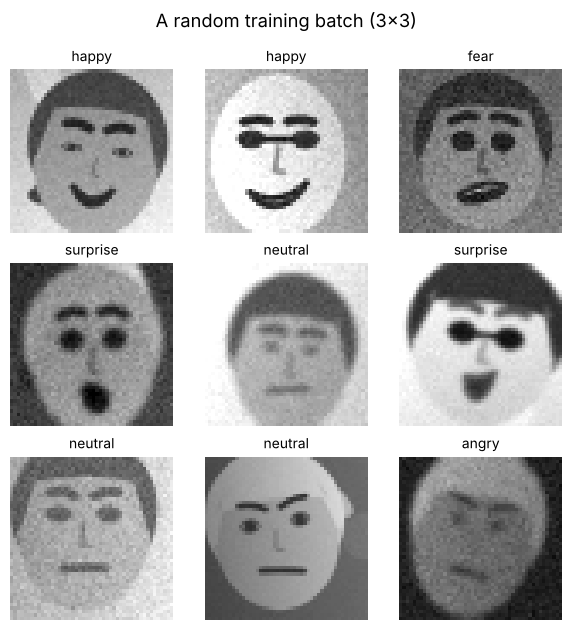

In [23]:
def show_grid(images: torch.Tensor, titles: list[str], nrows: int, ncols: int, figsize=(6, 6.4), suptitle=""):
    """Show (N, 1, H, W) float images in [-1, 1] in a grid with one title per image."""
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    for ax, img, title in zip(axes.ravel(), images, titles):
        ax.imshow(((img[0] + 1) * 127.5).numpy(), cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()


xb, yb = next(iter(DataLoader(TensorDataset(X_tr, Y_tr), batch_size=9, shuffle=True,
                              generator=torch.Generator().manual_seed(1))))
show_grid(xb, [idx2label[int(k)] for k in yb], 3, 3, suptitle="A random training batch (3×3)")

Some faces are easy to read, some are subtle, and a few labels may look wrong to you. They might be!
About 8% of SynthFaces-7 labels were deliberately swapped (and many more faces are simply subtle). Real
FER-2013 is noisier still: the original paper estimated that humans match the official label only about 65%
of the time (Section 1.1), so roughly one label in three is debatable.

A second, very informative check is the **mean image of each class**: average all training images of
a class pixel by pixel. Below them we plot each class mean *minus the overall mean*, which shows
where a class is brighter (red) or darker (blue) than an average face.

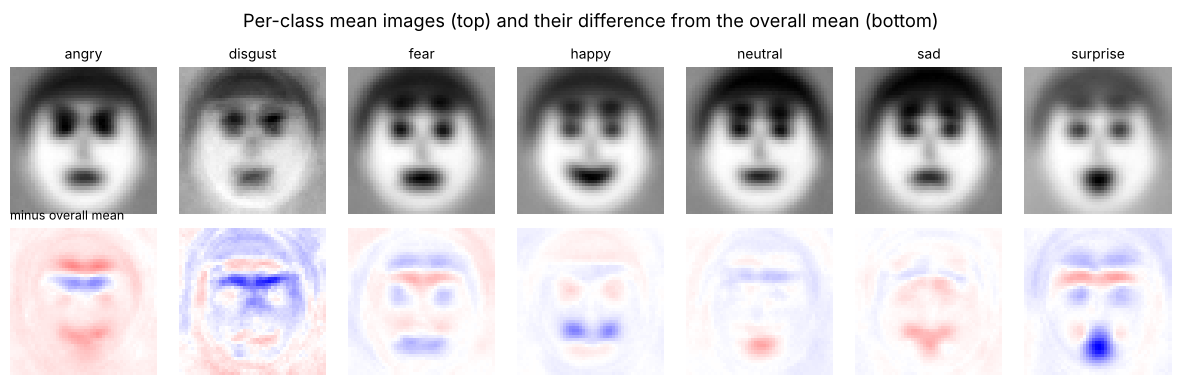

In [24]:
class_means = torch.stack([X_tr[Y_tr == k].mean(dim=0)[0] for k in range(NUM_CLASSES)])   # (K, 48, 48)
overall_mean = X_tr.mean(dim=0)[0]
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(12, 3.9))
lim = float((class_means - overall_mean).abs().max())
for k in range(NUM_CLASSES):
    axes[0, k].imshow(class_means[k].numpy(), cmap="gray")
    axes[0, k].set_title(idx2label[k], fontsize=10)
    axes[1, k].imshow((class_means[k] - overall_mean).numpy(), cmap="bwr", vmin=-lim, vmax=lim)
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[1, 0].set_title("minus overall mean", fontsize=9, loc="left")
fig.suptitle("Per-class mean images (top) and their difference from the overall mean (bottom)")
plt.tight_layout(); plt.show()

The means are blurry because faces sit at slightly different positions, but the difference maps
already reveal the discriminative regions: the mouth area for happy and surprise (open, dark mouths), the
eye area for fear and surprise (wide-open eyes), the brows for angry. A linear classifier on raw pixels
would essentially compare an image with such templates. The MLP can learn many such templates and combine them non-linearly.

### ✏️ Exercise 4: class mean images, vectorized

Write `class_mean_images(X, y, K)` that returns a tensor of shape `(K, H, W)` whose $k$-th slice is the
average of all images of class $k$ (`X` has shape `(N, 1, H, W)`, `y` has shape `(N,)`). Classes without
examples should give an all-zero image. Bonus: avoid a Python loop over classes (hint: `index_add_` or a one-hot matrix product).

In [25]:
# ✏️ Exercise 4: class mean images
def class_mean_images(X: torch.Tensor, y: torch.Tensor, K: int) -> torch.Tensor:
    """Per-class mean image, shape (K, H, W), with zeros for empty classes."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex4():
    X = torch.arange(4 * 2 * 3, dtype=torch.float32).reshape(4, 1, 2, 3)
    y = torch.tensor([0, 2, 0, 2])
    out = class_mean_images(X, y, 4)
    assert out.shape == (4, 2, 3), f"shape should be (4, 2, 3), got {tuple(out.shape)}"
    assert torch.allclose(out[0], (X[0, 0] + X[2, 0]) / 2), "class 0 mean is wrong"
    assert torch.allclose(out[2], (X[1, 0] + X[3, 0]) / 2), "class 2 mean is wrong"
    assert torch.all(out[1] == 0) and torch.all(out[3] == 0), "empty classes must be zeros"
    assert torch.allclose(class_mean_images(X_tr, Y_tr, NUM_CLASSES), class_means, atol=1e-5), "mismatch on real data"


run_check("Exercise 4", _test_ex4)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def class_mean_images(X, y, K):
    N, _, H, W = X.shape
    sums = torch.zeros(K, H * W).index_add_(0, y, X.reshape(N, H * W))   # add each image to its class row
    counts = torch.bincount(y, minlength=K).clamp(min=1).unsqueeze(1)    # avoid division by zero
    return (sums / counts).reshape(K, H, W)
```
`index_add_(0, y, rows)` adds row `i` of `rows` into row `y[i]` of `sums`, which is exactly a per-class sum.
The one-hot alternative is `F.one_hot(y, K).T.float() @ X.reshape(N, -1)`.
</details>

## 5. The pyramid MLP baseline

### 5.1 Architecture and parameter count

Our baseline is a "pyramid" MLP: each hidden layer is narrower than the previous one,
2304 → 256 → 128 → 64 → 7, with ReLU activations in between:

$$
\mathbf{h}_1 = \operatorname{ReLU}(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1),\quad
\mathbf{h}_2 = \operatorname{ReLU}(\mathbf{W}_2 \mathbf{h}_1 + \mathbf{b}_2),\quad
\mathbf{h}_3 = \operatorname{ReLU}(\mathbf{W}_3 \mathbf{h}_2 + \mathbf{b}_3),\quad
\mathbf{z} = \mathbf{W}_4 \mathbf{h}_3 + \mathbf{b}_4
$$

with $\mathbf{x} \in \mathbb{R}^{2304}$ (the flattened image), $\mathbf{W}_1 \in \mathbb{R}^{256 \times 2304}$,
$\mathbf{W}_2 \in \mathbb{R}^{128 \times 256}$, $\mathbf{W}_3 \in \mathbb{R}^{64 \times 128}$,
$\mathbf{W}_4 \in \mathbb{R}^{7 \times 64}$, and the **logits** $\mathbf{z} \in \mathbb{R}^{7}$ (one score per class).
A `Linear(n_in, n_out)` layer has $n_{\text{in}} \cdot n_{\text{out}}$ weights plus $n_{\text{out}}$ biases:

| Layer | Weights | Biases | Parameters |
|---|---|---|---|
| Linear(2304, 256) | 589,824 | 256 | 590,080 |
| Linear(256, 128) | 32,768 | 128 | 32,896 |
| Linear(128, 64) | 8,192 | 64 | 8,256 |
| Linear(64, 7) | 448 | 7 | 455 |
| **Total** | | | **631,687** |

More than 93% of all parameters sit in the first layer: the input dimension dominates the cost of an MLP.
Why a pyramid? The first layer can detect many simple patterns, and later layers combine them into fewer,
more abstract features, and the final layer only needs 64 well-chosen numbers to decide between 7 classes.

In [26]:
def make_mlp(hidden=(256, 128, 64), in_features=48 * 48, num_classes=NUM_CLASSES,
             batchnorm=False, dropout=0.0, upsample_to=None) -> nn.Sequential:
    """Pyramid MLP. Optional BatchNorm/Dropout after each hidden layer, optional input upsampling."""
    layers = []
    if upsample_to is not None:                       # resize inside the model (used in Section 6)
        layers.append(nn.Upsample(size=(upsample_to, upsample_to), mode="bilinear", align_corners=False))
        in_features = upsample_to * upsample_to
    layers.append(nn.Flatten())
    d = in_features
    for h in hidden:
        layers.append(nn.Linear(d, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        d = h
    layers.append(nn.Linear(d, num_classes))
    return nn.Sequential(*layers)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


torch.manual_seed(SEED)
baseline = make_mlp().to(DEVICE)
print(baseline)
print(f"trainable parameters: {count_params(baseline):,}")
for name, prm in baseline.named_parameters():
    print(f"  {name:10s} {str(tuple(prm.shape)):12s} {prm.numel():>9,}")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=2304, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=64, bias=True)
  (6): ReLU()
  (7): Linear(in_features=64, out_features=7, bias=True)
)
trainable parameters: 631,687
  1.weight   (256, 2304)    589,824
  1.bias     (256,)             256
  3.weight   (128, 256)      32,768
  3.bias     (128,)             128
  5.weight   (64, 128)        8,192
  5.bias     (64,)               64
  7.weight   (7, 64)            448
  7.bias     (7,)                 7


### 5.2 Loss: cross-entropy on logits

For one image with true class $y$ and logits $\mathbf{z}$, the softmax turns scores into probabilities
$p_k = e^{z_k} / \sum_j e^{z_j}$ and the **cross-entropy** loss is

$$
\ell(\mathbf{z}, y) = -\log p_y = -z_y + \log \sum_{j=1}^{K} e^{z_j}.
$$

`nn.CrossEntropyLoss` computes the right-hand side directly from the logits with the numerically stable
log-sum-exp trick, and averages over the batch. So the model must output **raw logits**: do not put a
softmax layer at the end.

> **Common pitfall.** Adding `nn.Softmax` as the last layer and then using `nn.CrossEntropyLoss` applies
> softmax twice. The loss still decreases, but the gradients become tiny and training stalls, because the
> "logits" are squashed into $[0, 1]$. The check below shows how much the loss changes.

In [27]:
z = torch.tensor([[2.0, 0.5, -1.0, 0.0, 0.3, -0.2, 1.0]])
y = torch.tensor([0])
manual = -z[0, 0] + torch.logsumexp(z[0], dim=0)
print(f"manual  -z_y + logsumexp(z) = {manual.item():.4f}")
print(f"nn.CrossEntropyLoss(z, y)   = {nn.CrossEntropyLoss()(z, y).item():.4f}")
print(f"wrong: CE(softmax(z), y)    = {nn.CrossEntropyLoss()(z.softmax(dim=1), y).item():.4f}   <- double softmax")

manual  -z_y + logsumexp(z) = 0.7274
nn.CrossEntropyLoss(z, y)   = 0.7274
wrong: CE(softmax(z), y)    = 1.6171   <- double softmax


### 5.3 A reusable training toolbox

The functions below are used by every experiment in this notebook:

* `train_one_epoch` loops over mini-batches: forward pass → loss → `zero_grad` → `backward` → `step`.
* `evaluate` computes loss and accuracy in **evaluation mode** (`model.eval()` + `torch.no_grad()`),
  which matters as soon as the model contains Dropout or BatchNorm (Section 9).
* `fit` runs several epochs, records a history for plotting, and supports augmentation and early stopping.

The training batches come from a `DataLoader` over the preloaded tensors, reshuffled every epoch by a
seeded generator, so each run is reproducible.

In [28]:
@torch.no_grad()
def predict_logits(model: nn.Module, X: torch.Tensor, batch_size: int = 1024) -> torch.Tensor:
    """Logits for all images in X (evaluation mode, no gradients)."""
    model.eval()
    return torch.cat([model(X[i:i + batch_size].to(DEVICE)).cpu() for i in range(0, len(X), batch_size)])


def evaluate(model: nn.Module, X: torch.Tensor, y: torch.Tensor) -> tuple[float, float]:
    """Return (mean cross-entropy, accuracy) of model on (X, y)."""
    logits = predict_logits(model, X)
    return F.cross_entropy(logits, y).item(), (logits.argmax(dim=1) == y).float().mean().item()


def train_one_epoch(model, loader, optimizer, loss_fn, augment=None) -> tuple[float, float]:
    """One pass over the loader. Returns (mean training loss, training accuracy) measured on the fly."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        if augment is not None:
            xb = augment(xb)
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, loss_fn=None, batch_size=256, augment=None, stopper=None,
        print_every=5, name="model", data=None) -> dict:
    """Train with mini-batches and evaluate on the validation set after every epoch. Returns a history dict."""
    X_train, Y_train, X_val, Y_val = data if data is not None else (X_tr, Y_tr, X_va, Y_va)
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, loader, optimizer, loss_fn, augment)
        va_loss, va_acc = evaluate(model, X_val, Y_val)
        for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc)):
            hist[k].append(v)
        stop = stopper is not None and stopper.step(va_loss, model)
        if ep % print_every == 0 or ep == epochs or stop:
            print(f"  [{name}] epoch {ep:3d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
                  f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - t0:5.1f} s")
        if stop:
            print(f"  [{name}] early stop at epoch {ep}, restoring the weights of epoch {stopper.best_epoch}")
            break
    if stopper is not None:
        stopper.restore(model)
    hist["seconds"] = time.time() - t0
    return hist

### 5.4 Training the baseline

**A note on the numbers.** From here on, the results quoted in the text (losses, accuracies, image counts,
epochs) come from the SynthFaces-7 run shown in the outputs, unless a number is explicitly labeled as a
FER-2013 number. With the real FER-2013 your numbers will differ. Section 14 says what to expect.

We train with mini-batch **SGD** (learning rate 0.01, momentum 0.9, batch size 256) for 25 epochs.
Momentum keeps a running average of past gradients, $\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla_{\boldsymbol\theta}\mathcal{L}$,
$\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\mathbf{v}$, which speeds up progress along consistent directions.
(Section 9 compares plain SGD, SGD with momentum and Adam.) One epoch = 30 mini-batch updates.

  [baseline] epoch   5 | train loss 1.820 acc 0.238 | val loss 1.819 acc 0.238 |   3.7 s


  [baseline] epoch  10 | train loss 1.778 acc 0.250 | val loss 1.773 acc 0.257 |   7.3 s


  [baseline] epoch  15 | train loss 1.606 acc 0.351 | val loss 1.633 acc 0.322 |  10.3 s


  [baseline] epoch  20 | train loss 1.458 acc 0.448 | val loss 1.576 acc 0.395 |  13.1 s


  [baseline] epoch  25 | train loss 1.385 acc 0.478 | val loss 1.542 acc 0.425 |  15.7 s


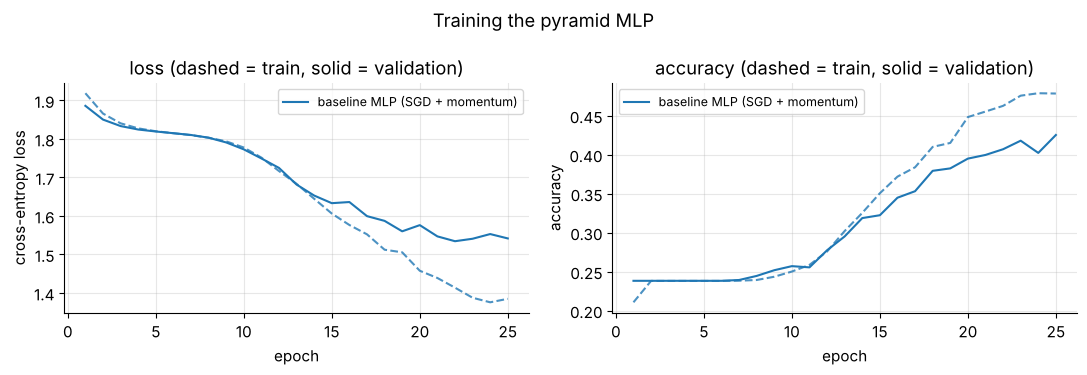

In [29]:
def plot_history(hists: dict, title: str = "", figsize=(11, 3.8)):
    """Plot loss and accuracy curves (train dashed, validation solid) for one or more runs."""
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    for i, (name, h) in enumerate(hists.items()):
        ep = np.arange(1, len(h["val_loss"]) + 1)
        color = f"C{i}"
        axes[0].plot(ep, h["train_loss"], "--", color=color, alpha=0.8)
        axes[0].plot(ep, h["val_loss"], "-", color=color, label=name)
        axes[1].plot(ep, h["train_acc"], "--", color=color, alpha=0.8)
        axes[1].plot(ep, h["val_acc"], "-", color=color, label=name)
    axes[0].set_ylabel("cross-entropy loss"); axes[1].set_ylabel("accuracy")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.legend(fontsize=9)
    axes[0].set_title("loss (dashed = train, solid = validation)")
    axes[1].set_title("accuracy (dashed = train, solid = validation)")
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()


torch.manual_seed(SEED)
baseline = make_mlp().to(DEVICE)
opt = torch.optim.SGD(baseline.parameters(), lr=0.01, momentum=0.9)
hist_base = fit(baseline, opt, epochs=25, name="baseline")
plot_history({"baseline MLP (SGD + momentum)": hist_base}, title="Training the pyramid MLP")

### 5.5 Reading the curves, then the test score

**First, the plateau.** For several epochs nothing seems to happen: the loss sits near 1.82 and the accuracy equals
the share of "happy" images. That loss value is no accident. A network that ignores the image and always outputs the
class frequencies $p_k$ (which it can do with its last-layer biases alone) has average cross-entropy
$-\sum_k p_k \log p_k$, the **entropy** of the label distribution, computed below. With PyTorch's default
initialization the hidden signals of a 4-layer network start small, so the gradient that would teach the network
to *use the pixels* is weak, and SGD needs a while before image features take over. Better optimizers
(Section 9) shorten this phase dramatically.

How to read the rest of the curves:

* **Training loss keeps falling** while **validation loss bottoms out and rises** → the model starts to
  memorize the training images (overfitting). The best epoch is where validation loss is lowest.
* The **gap** between training and validation accuracy measures overfitting. After 25 epochs of SGD it is still
  moderate, but with 0.63 M parameters and only 7.7k SynthFaces-7 training images (about 23k after the same split
  of the real FER-2013) it grows quickly once training gets faster (Section 9).
* The training numbers are measured *during* the epoch, while the weights are still changing (and
  with Dropout active, if any), so they are slightly pessimistic compared with a clean evaluation pass.

Only now, with all decisions made on validation data, do we look at the test set once.

In [30]:
p_train = np.bincount(y_tr, minlength=NUM_CLASSES) / len(y_tr)
print(f"entropy of the training labels: {-(p_train * np.log(p_train)).sum():.3f} nats "
      f"(the loss of 'predict the class frequencies'), and ln 7 = {np.log(7):.3f} (uniform guessing)")
base_val_loss, base_val_acc = evaluate(baseline, X_va, Y_va)
base_test_loss, base_test_acc = evaluate(baseline, X_te, Y_te)
best_ep = int(np.argmin(hist_base["val_loss"])) + 1
print(f"best validation loss at epoch {best_ep} ({min(hist_base['val_loss']):.3f}), and "
      f"final validation loss {hist_base['val_loss'][-1]:.3f}")
print(f"baseline MLP | validation accuracy {base_val_acc:.3f} | TEST accuracy {base_test_acc:.3f} "
      f"| majority-class baseline {counts_te.max() / counts_te.sum():.3f} | chance {1 / NUM_CLASSES:.3f}")
print(f"training time: {hist_base['seconds']:.0f} s on {DEVICE}")

entropy of the training labels: 1.819 nats (the loss of 'predict the class frequencies'); ln 7 = 1.946 (uniform guessing)
best validation loss at epoch 22 (1.534); final validation loss 1.542
baseline MLP | validation accuracy 0.425 | TEST accuracy 0.414 | majority-class baseline 0.230 | chance 0.143
training time: 16 s on cpu


### 5.6 Going deeper: why the plateau? A look at initialization

PyTorch initializes every `nn.Linear` layer with weights drawn uniformly from $[-1/\sqrt{n_{\text{in}}},\, 1/\sqrt{n_{\text{in}}}]$,
which has variance $\frac{1}{3 n_{\text{in}}}$. Follow the signal through one layer: a pre-activation is a sum of
$n_{\text{in}}$ terms, so its variance is about $n_{\text{in}} \cdot \operatorname{Var}(w) \cdot \mathbb{E}[x^2]$, and a ReLU keeps
about half of the second moment ($\mathbb{E}[\operatorname{ReLU}(z)^2] = \operatorname{Var}(z)/2$ for a symmetric $z$). Per layer, the
second moment of the signal is therefore multiplied by

$$
n_{\text{in}} \cdot \frac{1}{3 n_{\text{in}}} \cdot \frac{1}{2} = \frac{1}{6}.
$$

After three hidden layers the signal is tiny, the logits hardly depend on the image, and so do the gradients
that should teach the early layers. **He (Kaiming) initialization** uses $\operatorname{Var}(w) = 2/n_{\text{in}}$ instead,
which makes the factor exactly 1 and keeps the signal size constant through ReLU layers. Let us measure the activation
scale layer by layer, then train with He initialization for 10 epochs.

,default init,He init
input,0.4513,0.4513
after ReLU 1,0.1901,0.4624
after ReLU 2,0.0774,0.4458
after ReLU 3,0.0515,0.3875
logits,0.0648,0.6174


  [SGD + momentum, He init] epoch   5 | train loss 1.536 acc 0.416 | val loss 1.653 acc 0.341 |   3.0 s


  [SGD + momentum, He init] epoch  10 | train loss 1.283 acc 0.525 | val loss 1.607 acc 0.399 |   7.1 s


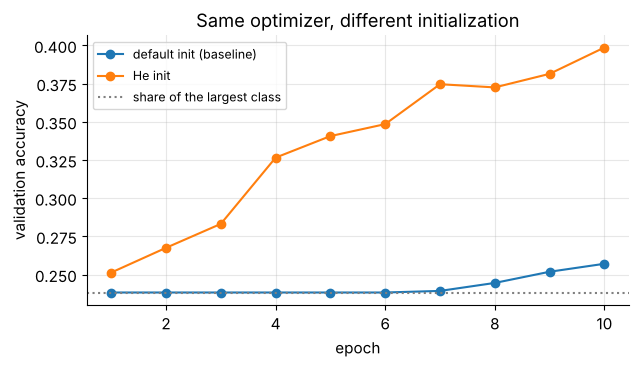

In [31]:
def he_init_(model: nn.Module) -> nn.Module:
    """Re-initialize every Linear layer with He (Kaiming) normal weights and zero biases."""
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model


def activation_rms(model: nn.Sequential, X: torch.Tensor) -> list[float]:
    """Root-mean-square of the signal after the input and after every ReLU / the final layer."""
    out, x = [X.flatten(1).pow(2).mean().sqrt().item()], X
    with torch.no_grad():
        for layer in model:
            x = layer(x)
            if isinstance(layer, nn.ReLU) or layer is model[-1]:
                out.append(x.pow(2).mean().sqrt().item())
    return out


torch.manual_seed(SEED)
rms_default = activation_rms(make_mlp(), X_tr[:512])
torch.manual_seed(SEED)
rms_he = activation_rms(he_init_(make_mlp()), X_tr[:512])
display(pd.DataFrame({"default init": rms_default, "He init": rms_he},
                     index=["input", "after ReLU 1", "after ReLU 2", "after ReLU 3", "logits"]).round(4))

torch.manual_seed(SEED)
mlp_he = he_init_(make_mlp()).to(DEVICE)
hist_he = fit(mlp_he, torch.optim.SGD(mlp_he.parameters(), lr=0.01, momentum=0.9), epochs=10, print_every=5,
              name="SGD + momentum, He init")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, 11), hist_base["val_acc"][:10], "o-", label="default init (baseline)")
ax.plot(range(1, 11), hist_he["val_acc"], "o-", label="He init")
ax.axhline(counts_tr.max() / counts_tr.sum(), color="gray", ls=":", label="share of the largest class")
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.set_title("Same optimizer, different initialization")
ax.legend(fontsize=9); plt.show()

With He initialization the signal keeps its size through the layers, and validation accuracy rises above the
majority-class level from the very first epoch instead of after a long plateau. (It also overfits sooner, which the later sections deal with.) For the rest of
the notebook we keep PyTorch's default initialization, since it is what you get unless you ask for something else.
Just remember that a long flat start of the loss curve is often an initialization or learning-rate problem, not a
data problem.

### ✏️ Exercise 5: parameter counting

Write `mlp_param_count(sizes)` for a fully connected network whose layer widths are listed in `sizes`
(input first, output last), e.g. `[2304, 256, 128, 64, 7]`. Each `Linear(a, b)` layer has $a \cdot b + b$
parameters. Then use it to answer: how many parameters does the same pyramid have if the input image is
128×128 instead of 48×48?

In [32]:
# ✏️ Exercise 5: parameter counting
def mlp_param_count(sizes: list[int]) -> int:
    """Number of weights + biases of an MLP with consecutive layer widths `sizes`."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex5():
    assert mlp_param_count([3, 2]) == 8, "Linear(3, 2) has 3*2 + 2 = 8 parameters"
    assert mlp_param_count([2304, 256, 128, 64, 7]) == count_params(make_mlp()), "must match PyTorch's count"
    assert mlp_param_count([128 * 128, 256, 128, 64, 7]) == 4_236_167, "the 128x128 pyramid has 4,236,167 parameters"


run_check("Exercise 5", _test_ex5)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def mlp_param_count(sizes):
    return sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))
```
For a 128×128 input only the first layer changes: $16384 \cdot 256 + 256 = 4{,}194{,}560$ parameters
instead of $590{,}080$, so the total grows from 631,687 to 4,236,167 (6.7 times more).
</details>

## 6. Does a bigger image help? 48×48 versus 128×128

A common reflex is to resize every image to a "standard" size such as 128×128 before training.
For FER-2013 that means **upsampling**: making new pixels by interpolation. With *bilinear*
interpolation each new pixel is a weighted average of the (up to) 4 nearest original pixels.

### 6.1 Upsampling cannot add information: a linear-algebra argument

Bilinear upsampling is a fixed **linear** map. Write the small image as a vector
$\mathbf{x} \in \mathbb{R}^{2304}$ and the big one as $\mathbf{x}' = U\mathbf{x} \in \mathbb{R}^{16384}$, where
$U \in \mathbb{R}^{16384 \times 2304}$ holds the interpolation weights. The first layer of an MLP on big images computes

$$
\mathbf{W}'\mathbf{x}' + \mathbf{b} = \mathbf{W}'U\mathbf{x} + \mathbf{b} = \mathbf{A}\mathbf{x} + \mathbf{b},
\qquad \mathbf{A} = \mathbf{W}'U \in \mathbb{R}^{256 \times 2304}.
$$

So "upsample, then `Linear(16384, 256)`" is *exactly* a `Linear(2304, 256)` layer with weight matrix
$\mathbf{A}$. Conversely, every $\mathbf{A}$ can be produced: if $U$ has full column rank (no information is
destroyed, so $\mathbf{x}$ can be recovered from $U\mathbf{x}$), then $U^{+}U = I$ for the pseudo-inverse $U^{+}$, and
$\mathbf{W}' = \mathbf{A}U^{+}$ gives $\mathbf{W}'U = \mathbf{A}$. Hence both networks represent **exactly the same set of
functions**. The big version only costs 7.1× more first-layer weights and compute (6.7× more parameters overall), and
the one thing that differs is the *optimization path* (gradient descent on $\mathbf{W}'$ is a re-parameterized gradient descent
on $\mathbf{A}$), which can make training slightly faster or slower but cannot unlock new decision rules.

Let us verify the full-rank claim numerically. Bilinear resizing acts on rows and columns separately, so
$U$ is a Kronecker product $U = R \otimes R$ of a $128 \times 48$ one-dimensional interpolation matrix $R$
with itself, and $\operatorname{rank}(R \otimes R) = \operatorname{rank}(R)^2$.

In [33]:
basis = torch.eye(48).reshape(48, 1, 1, 48)                          # 48 one-hot 1-D signals as 1x48 "images"
R = F.interpolate(basis, size=(1, 128), mode="bilinear", align_corners=False).reshape(48, 128).T   # 128 x 48
print("R shape:", tuple(R.shape), "| rank(R) =", torch.linalg.matrix_rank(R).item(),
      "| rank(U) = rank(R)^2 =", torch.linalg.matrix_rank(R).item() ** 2)
# Check the Kronecker structure on a real image: upsampling == R @ image @ R^T
img = X_tr[0:1]
up = F.interpolate(img, size=(128, 128), mode="bilinear", align_corners=False)[0, 0]
print("max |interpolate(img) - R img R^T| =", f"{(up - R @ img[0, 0] @ R.T).abs().max().item():.2e}")
print("each row of R sums to 1 (a weighted average):", torch.allclose(R.sum(dim=1), torch.ones(128)))

R shape: (128, 48) | rank(R) = 48 | rank(U) = rank(R)^2 = 2304
max |interpolate(img) - R img R^T| = 1.19e-07
each row of R sums to 1 (a weighted average): True


### 6.2 The experiment

Theory says "no gain". Let us check in practice. We put `nn.Upsample(128)` *inside* the model, so the
128×128 images are created on the fly for each batch (no upsampled copy of the dataset in memory, and for the real
FER-2013 that copy would take ≈470 MB, Section 4.2), and train both
networks with the same optimizer (Adam, learning rate $10^{-3}$, introduced in Section 9) for 4 epochs.

  [48x48] epoch   2 | train loss 1.739 acc 0.291 | val loss 1.681 acc 0.314 |   1.8 s


  [48x48] epoch   4 | train loss 1.559 acc 0.394 | val loss 1.585 acc 0.385 |   3.6 s


  [128x128] epoch   2 | train loss 1.690 acc 0.317 | val loss 1.666 acc 0.324 |  10.5 s


  [128x128] epoch   4 | train loss 1.535 acc 0.405 | val loss 1.578 acc 0.390 |  20.9 s


,parameters,best val acc,final val acc,seconds / epoch
input,,,,
48×48 input,631687,0.385,0.385,0.907
128×128 input,4236167,0.390,0.390,5.236


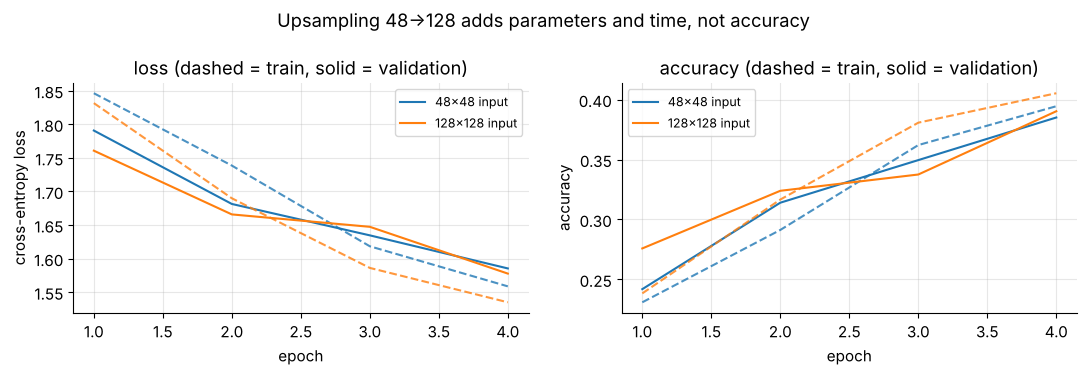

In [34]:
res_hist = {}
for size in (48, 128):
    torch.manual_seed(SEED)
    model = make_mlp(upsample_to=None if size == 48 else 128).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    res_hist[f"{size}×{size} input"] = fit(model, opt, epochs=4, print_every=2, name=f"{size}x{size}")
    res_hist[f"{size}×{size} input"]["params"] = count_params(model)

rows = [{"input": k, "parameters": h["params"], "best val acc": max(h["val_acc"]),
         "final val acc": h["val_acc"][-1], "seconds / epoch": h["seconds"] / len(h["val_acc"])}
        for k, h in res_hist.items()]
display(pd.DataFrame(rows).set_index("input").round(3))
plot_history(res_hist, title="Upsampling 48→128 adds parameters and time, not accuracy")

The validation curves of the two inputs track each other closely (small differences come from the different
optimization paths and random initialization), while the 128×128 model is several times slower per epoch.
**Conclusion:** keep the native 48×48 resolution for MLPs. Resizing is useful when you must *combine*
images of different sizes, or when a pretrained network expects a specific input size, but it never
creates detail that was not captured by the camera.

> **Olympiad tip.** "Composition of linear maps is linear" settles many architecture questions instantly:
> a stack of `Linear` layers *without* activations collapses to a single `Linear` layer, and any fixed linear
> preprocessing (resizing, a fixed filter, a change of basis) in front of a `Linear` layer can be absorbed
> into its weights.

## 7. Evaluation beyond accuracy

A single accuracy number hides *which* classes fail and *how*. With 7 imbalanced classes we need finer tools.

### 7.1 The confusion matrix

The **confusion matrix** $C \in \mathbb{N}^{K \times K}$ counts, for every pair of classes,
$C_{ij}$ = number of test images whose **true** class is $i$ and whose **predicted** class is $j$.
The diagonal holds correct predictions. Everything off the diagonal is a mistake, and its position tells you
which class was mistaken for which. A one-line way to build it: encode each (true, predicted) pair as the
single integer $K \cdot i + j$, count with `bincount`, and reshape to $K \times K$.

In [35]:
from sklearn.metrics import confusion_matrix as sk_confusion_matrix


def confusion_counts(y_true: np.ndarray, y_pred: np.ndarray, K: int) -> np.ndarray:
    """C[i, j] = number of examples with true class i and predicted class j."""
    return np.bincount(K * np.asarray(y_true) + np.asarray(y_pred), minlength=K * K).reshape(K, K)


test_logits = predict_logits(baseline, X_te)
test_pred = test_logits.argmax(dim=1).numpy()
cm = confusion_counts(y_te, test_pred, NUM_CLASSES)
assert np.array_equal(cm, sk_confusion_matrix(y_te, test_pred, labels=range(NUM_CLASSES)))
print("matches sklearn.metrics.confusion_matrix ✔")
display(pd.DataFrame(cm, index=[f"true {c}" for c in classes], columns=[f"pred {c}" for c in classes]))

matches sklearn.metrics.confusion_matrix ✔


,pred angry,pred disgust,pred fear,pred happy,pred neutral,pred sad,pred surprise
true angry,178,0,10,53,31,44,2
true disgust,16,0,0,6,2,13,0
true fear,29,0,90,81,21,95,31
true happy,48,0,28,359,44,57,13
true neutral,110,0,19,97,69,132,1
true sad,70,0,31,69,52,192,2
true surprise,13,0,70,66,6,40,102


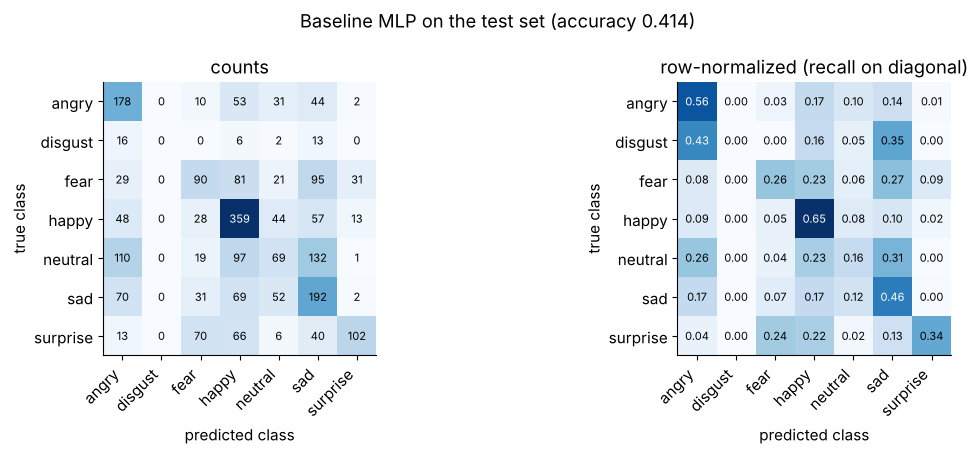

In [36]:
def plot_confusion(cm: np.ndarray, title: str):
    """Counts (left) and row-normalized rates (right, diagonal = per-class recall)."""
    rates = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for ax, mat, fmt, sub in ((axes[0], cm, "d", "counts"), (axes[1], rates, ".2f", "row-normalized (recall on diagonal)")):
        ax.imshow(mat, cmap="Blues")
        for (i, j), v in np.ndenumerate(mat):
            ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=8,
                    color="white" if v > 0.6 * mat.max() else "black")
        ax.set_xticks(range(NUM_CLASSES), labels=classes, rotation=45, ha="right")
        ax.set_yticks(range(NUM_CLASSES), labels=classes)
        ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title(sub); ax.grid(False)
    fig.suptitle(title); plt.tight_layout(); plt.show()


plot_confusion(cm, f"Baseline MLP on the test set (accuracy {np.trace(cm) / cm.sum():.3f})")

### 7.2 Precision, recall and F1 for every class

From the confusion matrix, for class $k$:

$$
\text{precision}_k = \frac{C_{kk}}{\sum_i C_{ik}} \;(\text{column sum}),\qquad
\text{recall}_k = \frac{C_{kk}}{\sum_j C_{kj}} \;(\text{row sum}),\qquad
F_{1,k} = \frac{2\,\text{precision}_k\,\text{recall}_k}{\text{precision}_k + \text{recall}_k}.
$$

*Precision* answers "when the model says *fear*, how often is it really fear?", and *recall* answers "of all
fear faces, how many did the model find?". F1 is their harmonic mean, which is small if *either* is small.
Two summaries treat all classes equally, no matter how many examples they have:

$$
\text{balanced accuracy} = \frac{1}{K}\sum_{k=1}^{K} \text{recall}_k, \qquad
\text{macro-}F_1 = \frac{1}{K}\sum_{k=1}^{K} F_{1,k}.
$$

**Worked example by hand.** Three classes A, B, C with 50, 30 and 5 test images:

| true \ predicted | A | B | C | recall |
|---|---|---|---|---|
| A (50) | **45** | 3 | 2 | 45/50 = 0.900 |
| B (30) | 5 | **20** | 5 | 20/30 = 0.667 |
| C (5) | 3 | 1 | **1** | 1/5 = 0.200 |
| precision | 45/53 = 0.849 | 20/24 = 0.833 | 1/8 = 0.125 | |

Accuracy $= (45+20+1)/85 = 0.776$ looks decent, but balanced accuracy $= (0.900+0.667+0.200)/3 = 0.589$ and
the F1 scores $0.874, 0.741, 0.154$ give macro-F1 $= 0.589$: class C is almost never recognized. The code
below reproduces these numbers and then applies the same function to our model.

In [37]:
def per_class_metrics(cm: np.ndarray) -> pd.DataFrame:
    """Precision, recall, F1 and support for every class from a confusion matrix."""
    tp = np.diag(cm).astype(float)
    precision = np.divide(tp, cm.sum(axis=0), out=np.zeros_like(tp), where=cm.sum(axis=0) > 0)
    recall = np.divide(tp, cm.sum(axis=1), out=np.zeros_like(tp), where=cm.sum(axis=1) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(tp), where=(precision + recall) > 0)
    return pd.DataFrame({"precision": precision, "recall": recall, "f1": f1, "support": cm.sum(axis=1)})


def summary_metrics(y_true, y_pred, K=NUM_CLASSES) -> dict:
    """Accuracy, balanced accuracy and macro-F1."""
    m = per_class_metrics(confusion_counts(y_true, y_pred, K))
    return {"accuracy": float(np.mean(np.asarray(y_true) == np.asarray(y_pred))),
            "balanced acc": float(m["recall"].mean()), "macro-F1": float(m["f1"].mean())}


toy = np.array([[45, 3, 2], [5, 20, 5], [3, 1, 1]])
toy_m = per_class_metrics(toy)
print("toy example: F1 =", toy_m["f1"].round(3).tolist(), "| balanced acc =", round(toy_m["recall"].mean(), 3),
      "| macro-F1 =", round(toy_m["f1"].mean(), 3))

base_metrics = per_class_metrics(cm)
base_metrics.index = classes
display(base_metrics.round(3))
base_summary = summary_metrics(y_te, test_pred)
print({k: round(v, 3) for k, v in base_summary.items()})

toy example: F1 = [0.874, 0.741, 0.154] | balanced acc = 0.589 | macro-F1 = 0.589


,precision,recall,f1,support
angry,0.384,0.560,0.455,318
disgust,0.000,0.000,0.000,37
fear,0.363,0.259,0.303,347
happy,0.491,0.654,0.561,549
neutral,0.307,0.161,0.211,428
sad,0.335,0.462,0.388,416
surprise,0.675,0.343,0.455,297


{'accuracy': 0.414, 'balanced acc': 0.348, 'macro-F1': 0.339}


In [38]:
from sklearn.metrics import balanced_accuracy_score, classification_report, f1_score

assert np.isclose(base_summary["balanced acc"], balanced_accuracy_score(y_te, test_pred))
assert np.isclose(base_summary["macro-F1"], f1_score(y_te, test_pred, average="macro", zero_division=0))
print("matches sklearn ✔  (balanced_accuracy_score, f1_score(average='macro'))\n")
print(classification_report(y_te, test_pred, target_names=classes, digits=3, zero_division=0))

matches sklearn ✔  (balanced_accuracy_score, f1_score(average='macro'))

              precision    recall  f1-score   support

       angry      0.384     0.560     0.455       318
     disgust      0.000     0.000     0.000        37
        fear      0.363     0.259     0.303       347
       happy      0.491     0.654     0.561       549
     neutral      0.307     0.161     0.211       428
         sad      0.335     0.462     0.388       416
    surprise      0.675     0.343     0.455       297

    accuracy                          0.414      2392
   macro avg      0.365     0.348     0.339      2392
weighted avg      0.413     0.414     0.395      2392



`classification_report` also prints a *weighted* average (each class weighted by its support), which
behaves like accuracy and hides small classes, and the *macro* average is the honest one for imbalanced data.

### 7.3 Which classes are confused with which?

Rank the off-diagonal cells. Adding $C_{ij} + C_{ji}$ gives the total confusion of the *unordered* pair.

In [39]:
def top_confusions(cm: np.ndarray, k: int = 6) -> pd.DataFrame:
    """The k largest off-diagonal entries of cm as (true, predicted, count, share of the true class)."""
    off = cm.astype(float).copy()
    np.fill_diagonal(off, -1)
    order = np.argsort(off, axis=None)[::-1][:k]
    rows = [(classes[i], classes[j], int(cm[i, j]), cm[i, j] / cm[i].sum())
            for i, j in zip(*np.unravel_index(order, cm.shape))]
    return pd.DataFrame(rows, columns=["true", "predicted as", "count", "share of true class"])


display(top_confusions(cm).round(3))
pair = cm + cm.T
np.fill_diagonal(pair, 0)
i, j = np.unravel_index(pair.argmax(), pair.shape)
print(f"most-confused unordered pair: {classes[i]} <-> {classes[j]} ({pair[i, j]} test images)")

,true,predicted as,count,share of true class
0,neutral,sad,132,0.308
1,neutral,angry,110,0.257
2,neutral,happy,97,0.227
3,fear,sad,95,0.274
4,fear,happy,81,0.233
5,sad,angry,70,0.168


most-confused unordered pair: neutral <-> sad (184 test images)


### 7.4 Look at the mistakes

Numbers tell you *how often* the model fails, and pictures tell you *why*. Below are the test images the model
got wrong with the **highest confidence** (largest softmax probability for the wrong class).

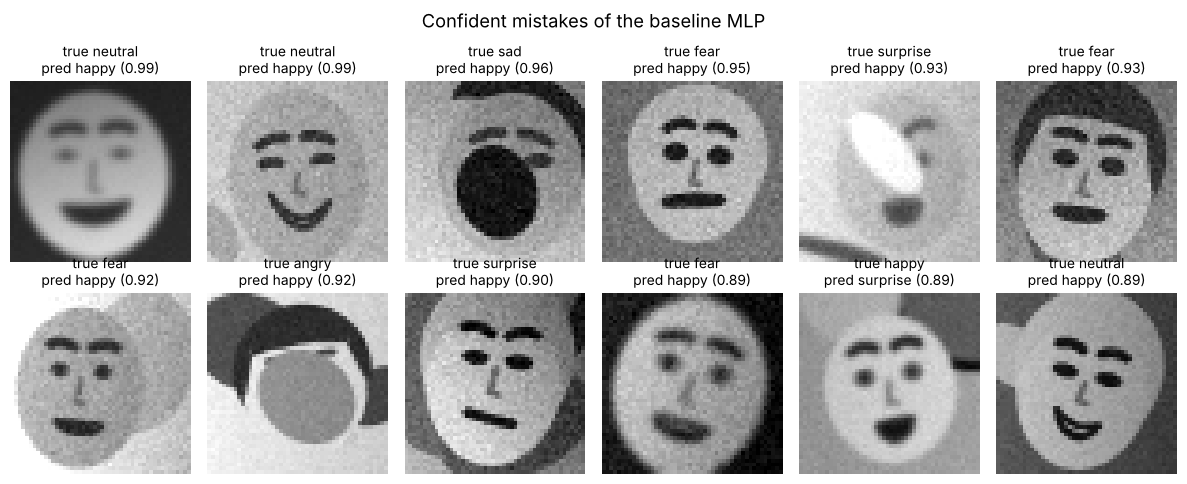

In [40]:
probs = test_logits.softmax(dim=1)
conf, pred = probs.max(dim=1)
wrong = np.flatnonzero(pred.numpy() != y_te)
worst = wrong[np.argsort(-conf.numpy()[wrong])][:12]
show_grid(X_te[worst], [f"true {idx2label[y_te[i]]}\npred {idx2label[int(pred[i])]} ({conf[i]:.2f})" for i in worst],
          2, 6, figsize=(12, 5), suptitle="Confident mistakes of the baseline MLP")

Typical causes you can spot in such grids (on real FER-2013 as well): faces that are shifted or rotated
away from the typical position, occluded mouths or eyes, very weak expressions, and labels that are
themselves debatable. Shifts and rotations are a *model* problem: the information is still in the image, but it
lands on different pixels, and Section 10 measures how much even a shift of a few pixels hurts an MLP. Occlusions
are partly a model problem (a better model can rely on the visible parts) and partly a *data* problem (a hidden
mouth cannot be read). Weak expressions and debatable labels are *data* problems that no model can fully fix.

**Quick check.** A model reaches 70% accuracy but 30% balanced accuracy on a 7-class test set. What can you
conclude?

<details>
<summary>Answer</summary>

The average per-class recall is low, so most classes are poorly recognized. The high accuracy must come from a few
large classes (perhaps a single dominant class) being predicted well. Large gaps between accuracy and balanced accuracy are a
red flag for imbalance-driven behavior, e.g. a model that predicts the majority class most of the time.
</details>

### ✏️ Exercise 6: confusion matrix with a loop-free trick

Implement `my_confusion(y_true, y_pred, K)` **without** using `bincount` or scikit-learn. Use
`np.add.at(C, (y_true, y_pred), 1)`, which adds 1 at every `(true, pred)` position, including repeated ones.

In [41]:
# ✏️ Exercise 6: confusion matrix
def my_confusion(y_true: np.ndarray, y_pred: np.ndarray, K: int) -> np.ndarray:
    """K x K integer matrix. Entry (i, j) counts true class i predicted as j."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex6():
    yt = np.array([0, 0, 1, 2, 2, 2])
    yp = np.array([0, 1, 1, 2, 0, 2])
    expected = np.array([[1, 1, 0], [0, 1, 0], [1, 0, 2]])
    out = my_confusion(yt, yp, 3)
    assert out.shape == (3, 3), f"shape should be (3, 3), got {out.shape}"
    assert np.array_equal(out, expected), f"got\n{out}"
    assert np.array_equal(my_confusion(y_te, test_pred, NUM_CLASSES), cm), "mismatch on the test predictions"


run_check("Exercise 6", _test_ex6)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def my_confusion(y_true, y_pred, K):
    C = np.zeros((K, K), dtype=np.int64)
    np.add.at(C, (np.asarray(y_true), np.asarray(y_pred)), 1)
    return C
```
Why not `C[y_true, y_pred] += 1`? With fancy indexing, repeated index pairs are written only once, so
duplicates would be lost. `np.add.at` performs an *unbuffered* addition that counts every occurrence.
</details>

### ✏️ Exercise 7: macro-F1 from a confusion matrix

Write `macro_f1(cm)` that returns the macro-averaged F1 score. Treat 0/0 as 0 (a class that is never
predicted has precision 0 by convention).

In [42]:
# ✏️ Exercise 7: macro-F1
def macro_f1(cm: np.ndarray) -> float:
    """Unweighted mean of the per-class F1 scores of confusion matrix cm."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex7():
    toy = np.array([[45, 3, 2], [5, 20, 5], [3, 1, 1]])
    assert abs(macro_f1(toy) - 0.58946) < 1e-4, f"toy example: expected 0.5895, got {macro_f1(toy):.4f}"
    never = np.array([[5, 0], [3, 0]])               # class 1 is never predicted
    assert abs(macro_f1(never) - (2 * 5 / 8 * 1 / (5 / 8 + 1)) / 2) < 1e-9, "0/0 must count as 0"
    assert abs(macro_f1(cm) - f1_score(y_te, test_pred, average="macro", zero_division=0)) < 1e-9


run_check("Exercise 7", _test_ex7)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def macro_f1(cm):
    tp = np.diag(cm).astype(float)
    pred_pos, true_pos = cm.sum(axis=0), cm.sum(axis=1)
    precision = np.where(pred_pos > 0, tp / np.maximum(pred_pos, 1), 0.0)
    recall = np.where(true_pos > 0, tp / np.maximum(true_pos, 1), 0.0)
    denom = precision + recall
    f1 = np.where(denom > 0, 2 * precision * recall / np.where(denom > 0, denom, 1), 0.0)
    return float(f1.mean())
```
An equivalent formula avoids precision and recall altogether: $F_{1,k} = 2C_{kk} / (\text{row}_k + \text{col}_k)$.
</details>

## 8. Fighting class imbalance with a weighted loss

### 8.1 The idea

With plain cross-entropy every training *image* counts equally, so the frequent classes dominate the gradient:
"happy" contributes about 14 times more terms than "disgust". A **class-weighted** loss multiplies each
example's loss by a weight $w_{y_i}$ that depends on its true class. The usual choice is *inverse frequency*,

$$
w_k = \frac{N}{K\,n_k},
$$

where $N$ is the number of training images and $n_k$ the number in class $k$. Then every class has the same
total weight, $n_k w_k = N/K$, and the average weight over all training images equals 1.

**How PyTorch averages.** With `nn.CrossEntropyLoss(weight=w)` and the default `reduction="mean"`, the batch loss is

$$
\mathcal{L} = \frac{\sum_{i} w_{y_i}\,\ell_i}{\sum_{i} w_{y_i}},
$$

a *weighted mean*, normalized by the sum of the weights in the batch (not by the batch size). Consequence:
multiplying all weights by a constant changes nothing, and only their *ratios* matter.

In [43]:
class_w = torch.tensor(len(y_tr) / (NUM_CLASSES * np.bincount(y_tr, minlength=NUM_CLASSES)), dtype=torch.float32)
display(pd.DataFrame({"train images": np.bincount(y_tr, minlength=NUM_CLASSES), "weight w_k": class_w.numpy()},
                     index=classes).round(3))

# Check PyTorch's weighted-mean formula on a mini-batch of 3 examples
logits3 = torch.tensor([[0.2, 0.1, 0.0, 2.0, 0.3, 0.0, 0.1],
                        [1.0, 0.5, 0.0, 0.2, 0.1, 0.4, 0.0],
                        [0.0, 0.0, 0.3, 0.1, 0.9, 1.1, 0.2]])
targets3 = torch.tensor([label2idx["happy"], label2idx["disgust"], label2idx["sad"]])
per_example = F.cross_entropy(logits3, targets3, reduction="none")
w3 = class_w[targets3]
print("per-example losses:", per_example.numpy().round(4), "| weights:", w3.numpy().round(3))
print(f"sum(w*l)/sum(w) = {(w3 * per_example).sum() / w3.sum():.4f} | "
      f"PyTorch = {F.cross_entropy(logits3, targets3, weight=class_w):.4f} | "
      f"with 10x weights = {F.cross_entropy(logits3, targets3, weight=10 * class_w):.4f} | "
      f"unweighted mean = {per_example.mean():.4f}")

,train images,weight w_k
angry,1045,1.047
disgust,127,8.612
fear,1078,1.015
happy,1823,0.600
neutral,1370,0.798
sad,1320,0.829
surprise,893,1.225


per-example losses: [0.6512 1.821  1.3106] | weights: [0.6   8.612 0.829]
sum(w*l)/sum(w) = 1.7089 | PyTorch = 1.7089 | with 10x weights = 1.7089 | unweighted mean = 1.2609


### 8.2 Experiment: unweighted versus weighted

We train two identical MLPs with the Adam optimizer (Section 9 explains it, and it converges much faster than plain
SGD) for 15 epochs. The only difference is the loss. We compare overall accuracy, balanced accuracy,
macro-F1, and the recall of the rarest class.

In [44]:
def test_report(model: nn.Module, name: str) -> dict:
    """Summary metrics on the test set plus the recall of the rarest class."""
    pred = predict_logits(model, X_te).argmax(dim=1).numpy()
    rep = {"model": name, **summary_metrics(y_te, pred)}
    rep["disgust recall"] = per_class_metrics(confusion_counts(y_te, pred, NUM_CLASSES))["recall"][label2idx["disgust"]]
    return rep


torch.manual_seed(SEED)
mlp_adam = make_mlp().to(DEVICE)
hist_adam = fit(mlp_adam, torch.optim.Adam(mlp_adam.parameters(), lr=1e-3), epochs=15, name="Adam, unweighted")

torch.manual_seed(SEED)
mlp_weighted = make_mlp().to(DEVICE)
hist_weighted = fit(mlp_weighted, torch.optim.Adam(mlp_weighted.parameters(), lr=1e-3), epochs=15,
                    loss_fn=nn.CrossEntropyLoss(weight=class_w.to(DEVICE)), name="Adam, weighted")

imbalance_table = pd.DataFrame([test_report(mlp_adam, "unweighted CE"),
                                test_report(mlp_weighted, "class-weighted CE")]).set_index("model")
train_pred = {m: predict_logits(m, X_tr).argmax(1).numpy() for m in (mlp_adam, mlp_weighted)}
imbalance_table["disgust recall on TRAINING images"] = [np.mean(train_pred[m][y_tr == disgust] == disgust)
                                                        for m in (mlp_adam, mlp_weighted)]
display(imbalance_table.round(3))

  [Adam, unweighted] epoch   5 | train loss 1.482 acc 0.436 | val loss 1.552 acc 0.390 |   3.1 s


  [Adam, unweighted] epoch  10 | train loss 1.235 acc 0.541 | val loss 1.509 acc 0.437 |   5.6 s


  [Adam, unweighted] epoch  15 | train loss 0.964 acc 0.660 | val loss 1.555 acc 0.454 |   7.6 s


  [Adam, weighted] epoch   5 | train loss 1.558 acc 0.354 | val loss 1.663 acc 0.348 |   2.1 s


  [Adam, weighted] epoch  10 | train loss 1.301 acc 0.468 | val loss 1.647 acc 0.377 |   4.0 s


  [Adam, weighted] epoch  15 | train loss 1.002 acc 0.580 | val loss 1.629 acc 0.412 |   6.2 s


,accuracy,balanced acc,macro-F1,disgust recall,disgust recall on TRAINING images
model,,,,,
unweighted CE,0.463,0.397,0.391,0.000,0.016
class-weighted CE,0.424,0.378,0.375,0.054,0.976


,angry,disgust,fear,happy,neutral,sad,surprise
true share,0.133,0.015,0.145,0.230,0.179,0.174,0.124
predicted share (unweighted),0.172,0.000,0.137,0.297,0.143,0.150,0.100
predicted share (weighted),0.151,0.023,0.162,0.199,0.166,0.175,0.123


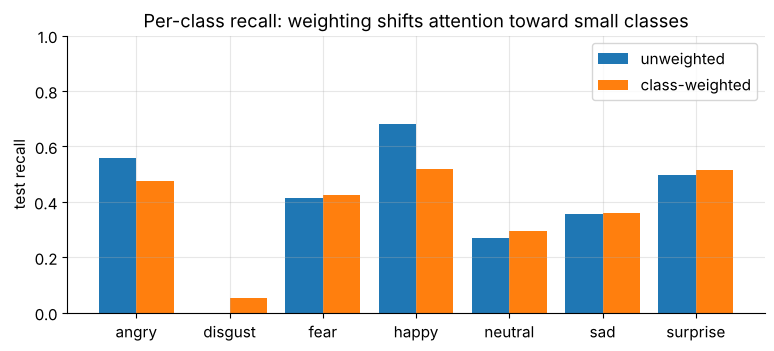

In [45]:
pred_unw = predict_logits(mlp_adam, X_te).argmax(1).numpy()
pred_w = predict_logits(mlp_weighted, X_te).argmax(1).numpy()
rec_unw = per_class_metrics(confusion_counts(y_te, pred_unw, NUM_CLASSES))["recall"]
rec_w = per_class_metrics(confusion_counts(y_te, pred_w, NUM_CLASSES))["recall"]
display(pd.DataFrame({"true share": counts_te / counts_te.sum(),
                      "predicted share (unweighted)": np.bincount(pred_unw, minlength=NUM_CLASSES) / len(y_te),
                      "predicted share (weighted)": np.bincount(pred_w, minlength=NUM_CLASSES) / len(y_te)},
                     index=classes).T.round(3))
fig, ax = plt.subplots(figsize=(9, 3.6))
pos = np.arange(NUM_CLASSES)
ax.bar(pos - 0.2, rec_unw, width=0.4, label="unweighted")
ax.bar(pos + 0.2, rec_w, width=0.4, label="class-weighted")
ax.set_xticks(pos, labels=classes); ax.set_ylabel("test recall"); ax.set_ylim(0, 1)
ax.set_title("Per-class recall: weighting shifts attention toward small classes"); ax.legend()
plt.show()

Read the tables carefully, because the result is instructive. Mechanically, weighting did what it promises. The
unweighted model over-predicts the big class (29.7% of its test predictions are "happy", against a true share of 23.0%)
and never predicts "disgust". The weighted model's predicted shares are much closer to the true ones, so recall rises for
most smaller classes and falls for "happy". But look at "disgust": the weighted model recognizes 97.6% of the **training**
"disgust" faces and only 5.4% of the **test** ones. Overall, balanced accuracy and macro-F1 did not improve.

Two lessons:

1. **Weights cannot create information.** There are only about 130 subtle "disgust" training faces in SynthFaces-7
   (the same split of the real FER-2013 keeps about 350) and 590k first-layer weights. Multiplying their loss by 8.6
   makes the network fit *those particular faces* faster, which is memorization, not a rule that transfers to new faces.
   Research on deep networks has found the same (Byrd and Lipton, 2019, in Going further): when a model can fit its
   training data almost perfectly, the effect of importance weights fades as training goes on.
2. **Weighting is a trade-off**, not a free improvement: every extra prediction for a small class is taken away from the
   others, and some of those are mistakes.

Weighting pays off when the rare class is actually learnable from the data at hand: more examples, an architecture with the
right inductive bias (Section 11), stronger regularization. Whether it helps is an empirical question, and you answer it on
the **validation** set using the metric you care about (balanced accuracy or macro-F1), never by assumption.

> **Going deeper.** Alternatives and complements to loss weighting: oversampling rare classes with
> `torch.utils.data.WeightedRandomSampler` (same expected gradient, different noise), the *focal loss* (down-weights easy
> examples), collecting more data for the rare class, and *logit adjustment*: training without weights and adding $\log w_k$
> to the logits at prediction time, which approximates the weighted decision rule when the predicted probabilities are
> well calibrated.

### ✏️ Exercise 8: inverse-frequency class weights

Implement `inverse_frequency_weights(labels, K)` returning a `float32` tensor $\mathbf{w}$ with
$w_k = N / (K n_k)$. Classes that do not occur in `labels` should get weight 0 (instead of dividing by zero).

In [46]:
# ✏️ Exercise 8: class weights
def inverse_frequency_weights(labels: np.ndarray, K: int) -> torch.Tensor:
    """w_k = N / (K * n_k), and 0 for classes with n_k = 0."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex8():
    w = inverse_frequency_weights(np.array([0, 0, 0, 1, 2, 2]), 4)
    assert w.dtype == torch.float32, f"dtype should be float32, got {w.dtype}"
    assert torch.allclose(w, torch.tensor([0.5, 1.5, 0.75, 0.0])), f"got {w}"
    assert torch.allclose(inverse_frequency_weights(y_tr, NUM_CLASSES), class_w), "mismatch with class_w"
    labels = np.array([0, 0, 0, 1, 2, 2])
    assert abs(inverse_frequency_weights(labels, 3)[labels].mean().item() - 1) < 1e-6, "mean weight per image must be 1"


run_check("Exercise 8", _test_ex8)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def inverse_frequency_weights(labels, K):
    n = np.bincount(labels, minlength=K).astype(np.float64)
    w = np.zeros(K)
    w[n > 0] = len(labels) / (K * n[n > 0])
    return torch.tensor(w, dtype=torch.float32)
```
With $N = 6$ and $K = 4$: class 0 has 3 images, so $w_0 = 6/(4 \cdot 3) = 0.5$, and class 1 has one, so $w_1 = 1.5$.
</details>

## 9. Making the MLP better

We now change **one thing at a time** and watch the validation metrics. The test set stays locked until the
summary table at the end of this section.

### 9.1 Optimizers: plain SGD, SGD with momentum, Adam

* **Plain SGD:** $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\, \mathbf{g}$ with the mini-batch gradient $\mathbf{g}$.
  One global step size for all 631,687 parameters.
* **SGD + momentum** (our baseline): accumulate $\mathbf{v} \leftarrow \beta\mathbf{v} + \mathbf{g}$ and step along $\mathbf{v}$.
  with $\beta = 0.9$ consistent directions are amplified up to $1/(1-\beta) = 10$ times.
* **Adam:** keeps running averages of the gradient, $\mathbf{m} \leftarrow \beta_1\mathbf{m} + (1-\beta_1)\mathbf{g}$, and of its
  square, $\mathbf{s} \leftarrow \beta_2\mathbf{s} + (1-\beta_2)\mathbf{g}^2$, then steps by
  $\eta\,\hat{\mathbf{m}} / (\sqrt{\hat{\mathbf{s}}} + \epsilon)$ (hats = bias-corrected averages). Each parameter gets its own
  effective step size of roughly $\eta$, whatever the scale of its gradient.

The baseline already gives us 25 epochs of SGD + momentum and Section 8 gave us 15 epochs of Adam (same seed, same
data order). We only need to train plain SGD.

  [plain SGD] epoch   5 | train loss 1.904 acc 0.238 | val loss 1.901 acc 0.238 |   1.7 s


  [plain SGD] epoch  10 | train loss 1.877 acc 0.238 | val loss 1.875 acc 0.238 |   3.3 s


  [plain SGD] epoch  15 | train loss 1.858 acc 0.238 | val loss 1.858 acc 0.238 |   4.8 s


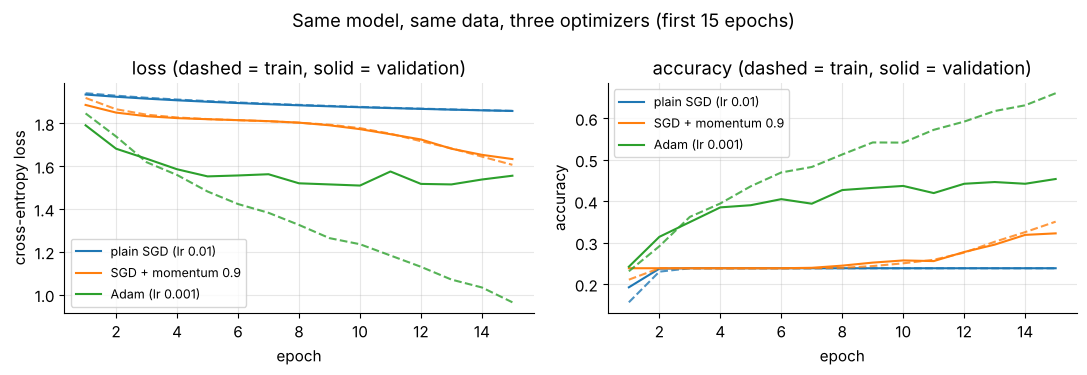

In [47]:
torch.manual_seed(SEED)
mlp_sgd = make_mlp().to(DEVICE)
hist_sgd = fit(mlp_sgd, torch.optim.SGD(mlp_sgd.parameters(), lr=0.01), epochs=15, name="plain SGD")
first15 = {k: v[:15] for k, v in hist_base.items() if isinstance(v, list)}
plot_history({"plain SGD (lr 0.01)": hist_sgd, "SGD + momentum 0.9": first15, "Adam (lr 0.001)": hist_adam},
             title="Same model, same data, three optimizers (first 15 epochs)")

* **Plain SGD** with learning rate 0.01 never leaves the majority-class plateau of Section 5.6 within 15 epochs: its
  validation accuracy stays exactly at the share of "happy".
* **Momentum** makes the same learning rate effectively 10 times larger. It also starts on the plateau but escapes it
  after about 10 epochs.
* **Adam** skips the plateau entirely. Because it divides each update by the typical size of that parameter's gradient,
  the *tiny* gradients caused by the small initial signal still produce steps of a useful size. But Adam also
  **overfits** first: its validation loss bottoms out around epoch 10 and then rises while the training loss keeps falling.

Faster optimizers make regularization and early stopping *more* important, not less.

### 9.2 Does input normalization matter? An experiment

Section 2 claimed that zero-centered inputs train better. Here is the test: the same Adam setup for 5 epochs on
inputs in $[0, 255]$ (raw), $[0, 1]$ and $[-1, 1]$. (The $[-1, 1]$ run is exactly the first 5 epochs of the Adam
run above: same seed and data order.)

In [48]:
input_ranges = {"[-1, 1]": lambda X: X,                       # our default
                "[0, 1]": lambda X: (X + 1) / 2,
                "raw [0, 255]": lambda X: (X + 1) * 127.5}
torch.manual_seed(SEED)
probe = make_mlp()                                             # a freshly initialized network
with torch.no_grad():
    pre_std = {name: probe[1](probe[0](f(X_tr[:512]))).std().item() for name, f in input_ranges.items()}
print("std of first-layer pre-activations at initialization:", {k: round(v, 2) for k, v in pre_std.items()})

norm_hist = {"[-1, 1]": {k: v[:5] for k, v in hist_adam.items() if isinstance(v, list)}}
for name in ("[0, 1]", "raw [0, 255]"):
    f = input_ranges[name]
    torch.manual_seed(SEED)
    m = make_mlp().to(DEVICE)
    norm_hist[name] = fit(m, torch.optim.Adam(m.parameters(), lr=1e-3), epochs=5, print_every=5, name=name,
                          data=(f(X_tr), Y_tr, f(X_va), Y_va))
display(pd.DataFrame({k: {"pre-activation std at init": pre_std[k], "train loss epoch 1": h["train_loss"][0],
                          "val loss after 5 epochs": h["val_loss"][-1], "val acc after 5 epochs": h["val_acc"][-1]}
                      for k, h in norm_hist.items()}).T.round(3))

std of first-layer pre-activations at initialization: {'[-1, 1]': 0.27, '[0, 1]': 0.32, 'raw [0, 255]': 82.23}


  [[0, 1]] epoch   5 | train loss 1.769 acc 0.253 | val loss 1.753 acc 0.266 |   2.1 s


  [raw [0, 255]] epoch   5 | train loss 1.880 acc 0.239 | val loss 2.231 acc 0.191 |   2.2 s


,pre-activation std at init,train loss epoch 1,val loss after 5 epochs,val acc after 5 epochs
"[-1, 1]",0.266,1.846,1.552,0.390
"[0, 1]",0.323,1.844,1.753,0.266
"raw [0, 255]",82.229,15.474,2.231,0.191


The measurement confirms Section 2.2. With raw pixel values the first-layer pre-activations at initialization are about
300 times larger than with inputs in $[-1, 1]$, the initial logits are huge and essentially random (the first-epoch
training loss is above 15 instead of about 1.85), and after 5 epochs the validation accuracy is even *below* the
majority-class rate. Inputs in $[0, 1]$ have a reasonable scale but are all
positive, and they still learn clearly more slowly than zero-centered inputs. Normalizing costs one line of code, but skipping
it can cost most of your training budget. (BatchNorm, next, re-normalizes the hidden layers during training and makes
networks much less sensitive to such scale problems.)

### 9.3 Three regularizers: BatchNorm, Dropout, weight decay

* **Batch normalization** (`nn.BatchNorm1d`) standardizes every hidden unit over the mini-batch,
  $\hat{h} = (h - \mu_B)/\sqrt{\sigma_B^2 + \epsilon}$, then rescales it with learnable $\gamma, \beta$: $\gamma\hat{h} + \beta$.
  It keeps activations in a well-behaved range, which allows larger steps, and the batch-to-batch noise in
  $\mu_B, \sigma_B$ also acts as a mild regularizer. At evaluation time it uses *running averages* of $\mu$ and $\sigma^2$
  collected during training instead of batch statistics.
* **Dropout** (`nn.Dropout(p)`) sets each hidden activation to 0 with probability $p$ during training and scales
  the survivors by $1/(1-p)$, so the expected value is unchanged. The network cannot rely on any single unit and
  learns redundant features. At evaluation time it does nothing.
* **Weight decay** shrinks all weights a little at every step, $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\lambda\boldsymbol\theta$,
  preferring small weights (like an L2 penalty $\frac{\lambda}{2}\lVert\boldsymbol\theta\rVert^2$). `AdamW` applies it
  *decoupled* from Adam's adaptive scaling, which is the recommended way to combine the two.

> **Common pitfall.** BatchNorm and Dropout behave differently in training and evaluation. Forgetting
> `model.eval()` before validation gives noisy, pessimistic scores (Dropout still active) and can even
> change the BatchNorm running statistics, and forgetting `model.train()` afterwards silently turns off Dropout.
> Our `evaluate` and `train_one_epoch` set the mode explicitly every time.

In [49]:
torch.manual_seed(SEED)
demo = make_mlp(batchnorm=True, dropout=0.3)
xb = X_tr[:256]
demo.train()
out_a, out_b = demo(xb), demo(xb)
demo.eval()
out_c, out_d = demo(xb), demo(xb)
print(demo)
print(f"train mode: two passes on the same batch differ by {(out_a - out_b).abs().max():.3f} (Dropout is random)")
print(f"eval mode : two passes on the same batch differ by {(out_c - out_d).abs().max():.3f} (deterministic)")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=2304, out_features=256, bias=True)
  (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): ReLU()
  (4): Dropout(p=0.3, inplace=False)
  (5): Linear(in_features=256, out_features=128, bias=True)
  (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (7): ReLU()
  (8): Dropout(p=0.3, inplace=False)
  (9): Linear(in_features=128, out_features=64, bias=True)
  (10): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (11): ReLU()
  (12): Dropout(p=0.3, inplace=False)
  (13): Linear(in_features=64, out_features=7, bias=True)
)
train mode: two passes on the same batch differ by 2.344 (Dropout is random)
eval mode : two passes on the same batch differ by 0.000 (deterministic)


### 9.4 Early stopping

Instead of guessing the number of epochs, watch the validation loss and **stop** when it has not improved for
`patience` epochs, then **restore** the weights from the best epoch. The class below keeps a copy of the best
weights in memory (`state_dict` = dictionary of all parameter and buffer tensors).

  [BN + Dropout + AdamW + early stopping] epoch   5 | train loss 1.640 acc 0.342 | val loss 1.616 acc 0.355 |   2.7 s


  [BN + Dropout + AdamW + early stopping] epoch  10 | train loss 1.486 acc 0.416 | val loss 1.543 acc 0.399 |   5.4 s


  [BN + Dropout + AdamW + early stopping] epoch  15 | train loss 1.373 acc 0.480 | val loss 1.471 acc 0.428 |   8.1 s


  [BN + Dropout + AdamW + early stopping] epoch  20 | train loss 1.278 acc 0.516 | val loss 1.453 acc 0.444 |  10.7 s


  [BN + Dropout + AdamW + early stopping] epoch  25 | train loss 1.211 acc 0.545 | val loss 1.419 acc 0.470 |  13.5 s


  [BN + Dropout + AdamW + early stopping] epoch  27 | train loss 1.159 acc 0.568 | val loss 1.490 acc 0.447 |  14.5 s
  [BN + Dropout + AdamW + early stopping] early stop at epoch 27; restoring the weights of epoch 23


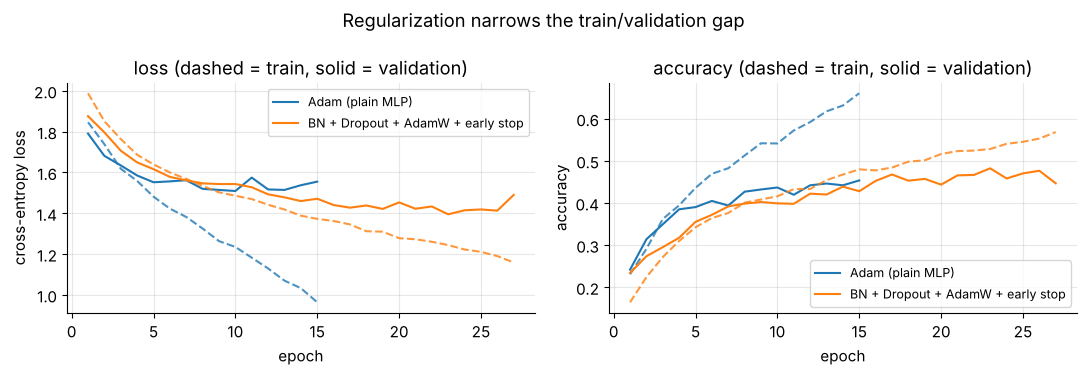

In [50]:
import copy


class EarlyStopping:
    """Stop when the validation loss has not improved by min_delta for `patience` epochs, and keep the best weights."""

    def __init__(self, patience: int = 4, min_delta: float = 1e-3):
        self.patience, self.min_delta = patience, min_delta
        self.best_loss, self.best_epoch, self.epoch, self.bad_epochs = float("inf"), 0, 0, 0
        self.best_state = None

    def step(self, val_loss: float, model: nn.Module) -> bool:
        """Record one epoch and return True if training should stop."""
        self.epoch += 1
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss, self.best_epoch, self.bad_epochs = val_loss, self.epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

    def restore(self, model: nn.Module) -> None:
        if self.best_state is not None:
            model.load_state_dict(self.best_state)


torch.manual_seed(SEED)
mlp_reg = make_mlp(batchnorm=True, dropout=0.3).to(DEVICE)
stopper_reg = EarlyStopping(patience=4)
hist_reg = fit(mlp_reg, torch.optim.AdamW(mlp_reg.parameters(), lr=1e-3, weight_decay=1e-2), epochs=40,
               stopper=stopper_reg, name="BN + Dropout + AdamW + early stopping")
plot_history({"Adam (plain MLP)": hist_adam, "BN + Dropout + AdamW + early stop": hist_reg},
             title="Regularization narrows the train/validation gap")

### ✏️ Exercise 9: the early-stopping rule as a pure function

Write `stop_epoch(val_losses, patience, min_delta)` that replays the rule above on a list of validation losses
and returns `(stop, best)`: the 1-based epoch at which training stops (or `len(val_losses)` if it never stops)
and the 1-based best epoch. An epoch counts as an improvement only if its loss is below `best_loss - min_delta`.

In [51]:
# ✏️ Exercise 9: early stopping rule
def stop_epoch(val_losses: list[float], patience: int, min_delta: float = 0.0) -> tuple[int, int]:
    """Return (stop epoch, best epoch), both 1-based."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex9():
    assert stop_epoch([1.0, 0.8, 0.7, 0.75, 0.72, 0.71], patience=3) == (6, 3), "stops 3 epochs after the best"
    assert stop_epoch([1.0, 0.9, 0.8], patience=2) == (3, 3), "never stops -> (len, best)"
    assert stop_epoch([1.0, 0.95, 0.94, 0.93], patience=2, min_delta=0.06) == (3, 1), "tiny gains do not count"
    assert stop_epoch([0.5], patience=1) == (1, 1)


run_check("Exercise 9", _test_ex9)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def stop_epoch(val_losses, patience, min_delta=0.0):
    best_loss, best, bad = float("inf"), 0, 0
    for epoch, loss in enumerate(val_losses, start=1):
        if loss < best_loss - min_delta:
            best_loss, best, bad = loss, epoch, 0
        else:
            bad += 1
        if bad >= patience:
            return epoch, best
    return len(val_losses), best
```
In the third test, 0.95 is not below $1.0 - 0.06 = 0.94$ and 0.94 is not *strictly* below 0.94, so no epoch after the first
counts as an improvement and training stops at epoch 3.
</details>

### 9.5 Data augmentation: flips and small shifts

**Augmentation** creates new, plausible training images from existing ones with transformations that do
not change the label. For faces, two safe choices are:

* **horizontal flip**: a mirrored smile is still a smile (expressions are roughly left-right symmetric, and
  for one-sided expressions the mirror image is just as valid an example),
* **small shifts** of a few pixels: the face detector that cropped the images is never perfectly accurate.

Vertical flips or large rotations would produce faces that never occur in the data, so we avoid them. Because
our images are preloaded, we augment whole **batches** of tensors inside the training loop: every epoch sees
a different random version of each image. Shifting needs a rule for the pixels that enter at the border, and we
*replicate* the edge pixels (`mode="replicate"`), which looks more natural than a black band.

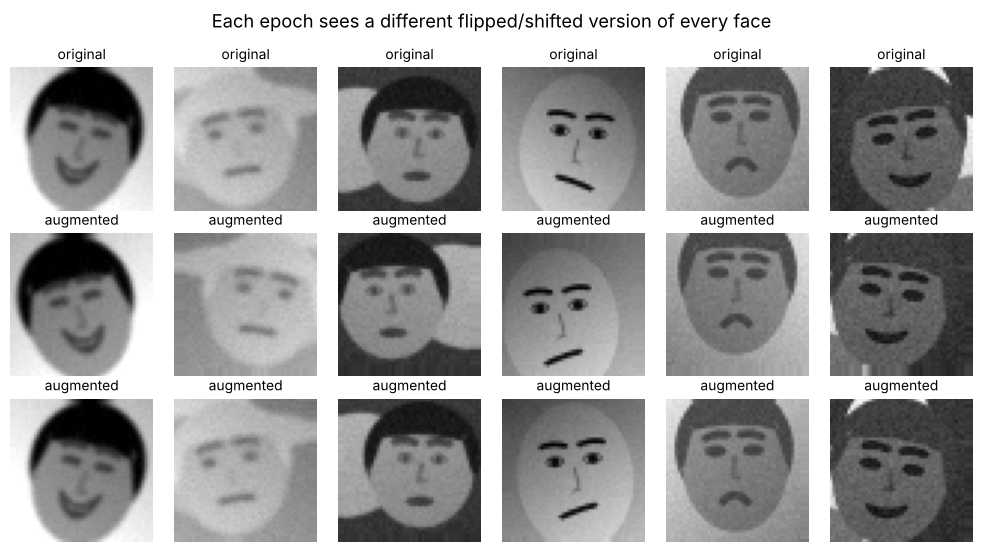

In [52]:
def translate(X: torch.Tensor, dx: int, dy: int) -> torch.Tensor:
    """Shift a batch (N, C, H, W) by dx pixels right and dy pixels down, replicating the border pixels."""
    p = max(abs(dx), abs(dy))
    if p == 0:
        return X
    H, W = X.shape[-2:]
    Xp = F.pad(X, (p, p, p, p), mode="replicate")
    return Xp[..., p - dy:p - dy + H, p - dx:p - dx + W]


def augment_batch(X: torch.Tensor, max_shift: int = 3, flip: bool = True) -> torch.Tensor:
    """Random horizontal flip (prob 0.5) and a random shift of up to max_shift pixels per image."""
    N, _, H, W = X.shape
    if flip:
        mirror = torch.rand(N) < 0.5
        X = torch.where(mirror[:, None, None, None], X.flip(-1), X)
    if max_shift > 0:
        s = max_shift
        Xp = F.pad(X, (s, s, s, s), mode="replicate")
        off = torch.randint(0, 2 * s + 1, (N, 2))                      # crop offsets per image
        rows = torch.arange(H)[None, :] + off[:, :1]                     # (N, H)
        cols = torch.arange(W)[None, :] + off[:, 1:]                     # (N, W)
        X = Xp[torch.arange(N)[:, None, None], 0, rows[:, :, None], cols[:, None, :]].unsqueeze(1)
    return X


torch.manual_seed(3)
xb = X_tr[:6]
show_grid(torch.cat([xb, augment_batch(xb), augment_batch(xb)]), ["original"] * 6 + ["augmented"] * 12, 3, 6,
          figsize=(10, 5.6), suptitle="Each epoch sees a different flipped/shifted version of every face")

The batch version uses *advanced indexing*: `rows[i]` and `cols[i]` hold the row and column indices of the
48×48 crop for image `i`, and indexing with three broadcast index arrays of shapes `(N,1,1)`, `(N,H,1)` and
`(N,1,W)` gathers all crops at once, without a Python loop. Now train the regularized MLP again, this time with augmentation.

  [regularized + augmentation] epoch   5 | train loss 1.781 acc 0.259 | val loss 1.718 acc 0.294 |   3.9 s


  [regularized + augmentation] epoch  10 | train loss 1.698 acc 0.297 | val loss 1.620 acc 0.338 |   7.6 s


  [regularized + augmentation] epoch  15 | train loss 1.653 acc 0.329 | val loss 1.550 acc 0.382 |  11.3 s


  [regularized + augmentation] epoch  20 | train loss 1.606 acc 0.352 | val loss 1.495 acc 0.406 |  15.1 s


  [regularized + augmentation] epoch  25 | train loss 1.570 acc 0.374 | val loss 1.428 acc 0.448 |  18.7 s


  [regularized + augmentation] epoch  30 | train loss 1.544 acc 0.388 | val loss 1.436 acc 0.455 |  22.1 s


  [regularized + augmentation] epoch  35 | train loss 1.519 acc 0.400 | val loss 1.383 acc 0.477 |  25.5 s


  [regularized + augmentation] epoch  40 | train loss 1.485 acc 0.418 | val loss 1.352 acc 0.496 |  29.1 s


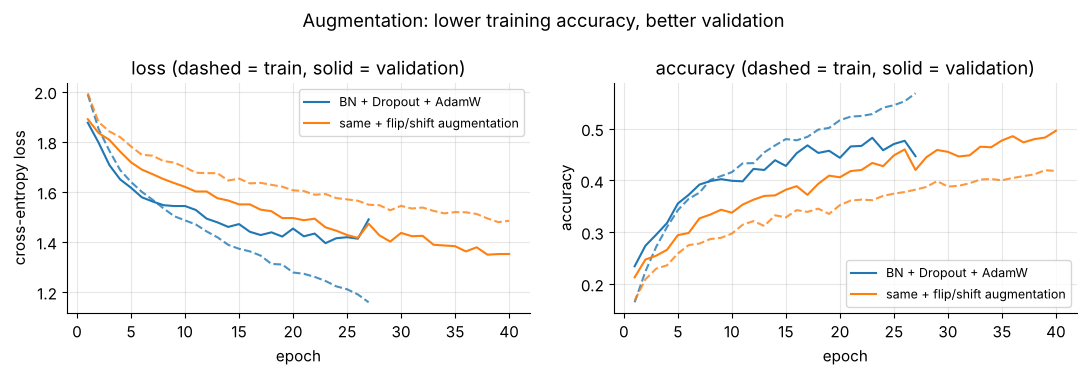

In [53]:
torch.manual_seed(SEED)
mlp_aug = make_mlp(batchnorm=True, dropout=0.3).to(DEVICE)
stopper_aug = EarlyStopping(patience=4)
hist_aug = fit(mlp_aug, torch.optim.AdamW(mlp_aug.parameters(), lr=1e-3, weight_decay=1e-2), epochs=40,
               augment=augment_batch, stopper=stopper_aug, name="regularized + augmentation")
plot_history({"BN + Dropout + AdamW": hist_reg, "same + flip/shift augmentation": hist_aug},
             title="Augmentation: lower training accuracy, better validation")

### ✏️ Exercise 10: shifting with a constant fill

Implement `shift_with_fill(img, dx, dy, fill)` for a single 2-D tensor `img` of shape `(H, W)`: the output pixel at
`(r, c)` equals `img[r - dy, c - dx]` when that position is inside the image and `fill` otherwise.
(Positive `dx` moves the content right, positive `dy` moves it down.)

In [54]:
# ✏️ Exercise 10: shift with a constant fill value
def shift_with_fill(img: torch.Tensor, dx: int, dy: int, fill: float = -1.0) -> torch.Tensor:
    """Shift a 2-D image by (dx, dy). Uncovered pixels get the value `fill`."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex10():
    img = torch.arange(1.0, 10.0).reshape(3, 3)              # [[1,2,3],[4,5,6],[7,8,9]]
    assert torch.equal(shift_with_fill(img, 1, 0, 0.0), torch.tensor([[0., 1, 2], [0, 4, 5], [0, 7, 8]])), "dx=1"
    assert torch.equal(shift_with_fill(img, 0, -1, 0.0), torch.tensor([[4., 5, 6], [7, 8, 9], [0, 0, 0]])), "dy=-1"
    assert torch.equal(shift_with_fill(img, -2, 1, 9.0), torch.tensor([[9., 9, 9], [3, 9, 9], [6, 9, 9]])), "dx=-2, dy=1"
    assert torch.equal(shift_with_fill(img, 0, 0), img), "zero shift must return the same values"
    assert torch.all(shift_with_fill(img, 5, 0) == -1.0), "shifting out of the image leaves only fill"


run_check("Exercise 10", _test_ex10)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def shift_with_fill(img, dx, dy, fill=-1.0):
    H, W = img.shape
    out = torch.full_like(img, fill)
    r0, r1 = max(0, dy), min(H, H + dy)          # destination rows that receive content
    c0, c1 = max(0, dx), min(W, W + dx)
    if r0 < r1 and c0 < c1:
        out[r0:r1, c0:c1] = img[r0 - dy:r1 - dy, c0 - dx:c1 - dx]
    return out
```
The destination block `[r0:r1, c0:c1]` and the source block are the same size, and the `if` handles shifts larger than the image.
</details>

### 9.6 Scoreboard

Time to open the test set for all MLP variants. The validation set guided the choices, and the test columns are the
honest estimate of performance on new data.

In [55]:
variants = {"baseline (SGD + momentum)": (baseline, hist_base), "plain SGD": (mlp_sgd, hist_sgd),
            "Adam": (mlp_adam, hist_adam), "Adam + class weights": (mlp_weighted, hist_weighted),
            "BN + Dropout + AdamW + early stop": (mlp_reg, hist_reg), "  ... + augmentation": (mlp_aug, hist_aug)}
rows = []
for name, (model, h) in variants.items():
    rep = test_report(model, name)
    rep.update({"val acc": evaluate(model, X_va, Y_va)[1], "epochs": len(h["val_acc"]), "seconds": h["seconds"]})
    rows.append(rep)
scoreboard = pd.DataFrame(rows).set_index("model")[["val acc", "accuracy", "balanced acc", "macro-F1",
                                                    "disgust recall", "epochs", "seconds"]]
scoreboard = scoreboard.rename(columns={"accuracy": "test acc"})
display(scoreboard.round(3))

,val acc,test acc,balanced acc,macro-F1,disgust recall,epochs,seconds
model,,,,,,,
baseline (SGD + momentum),0.425,0.414,0.348,0.339,0.000,25,15.722
plain SGD,0.238,0.230,0.143,0.053,0.000,15,4.813
Adam,0.454,0.463,0.397,0.391,0.000,15,7.572
Adam + class weights,0.412,0.424,0.378,0.375,0.054,15,6.155
BN + Dropout + AdamW + early stop,0.482,0.469,0.399,0.398,0.000,27,14.509
... + augmentation,0.480,0.501,0.429,0.424,0.000,40,29.087


How to read the scoreboard:

* **The ladder works.** Test accuracy climbs from 0.414 (baseline) to 0.463 (Adam), 0.469 (BatchNorm + Dropout +
  weight decay + early stopping) and 0.501 (+ augmentation): almost 9 points gained without a single new image.
  On validation *accuracy* the last two rows are tied (0.482 vs 0.480), and the augmented model's advantage shows up
  in its lower validation *loss* (the curves in Section 9.5, and the quantity early stopping monitors) and is then
  confirmed on the test set. With about 1.9k validation images, differences of one or two accuracy points are
  within noise.
* **Validation and test agree** within about two points for every model, so our validation-based decisions did not
  overfit the validation set.
* **Plain SGD marks the floor:** its 0.230 is exactly the share of "happy" in the test set, i.e. no learning at all.
* **Accuracy is not everything:** compare the balanced-accuracy and macro-F1 columns, and the recall of "disgust",
  which stays near zero for every MLP.
* **Cost:** the best MLP needed the most epochs, because augmentation makes the training task harder. The training
  accuracy is *lower* than the validation accuracy for most of its run.

## 10. What an MLP cannot see: translations, pixel order and templates

### 10.1 Shift the test images by a few pixels

A face moved 4 pixels to the right is obviously the same face with the same expression. Is the MLP of the
same opinion? We shift every test image horizontally by $d \in \{-6, \dots, 6\}$ pixels (replicating the border) and
measure the accuracy.

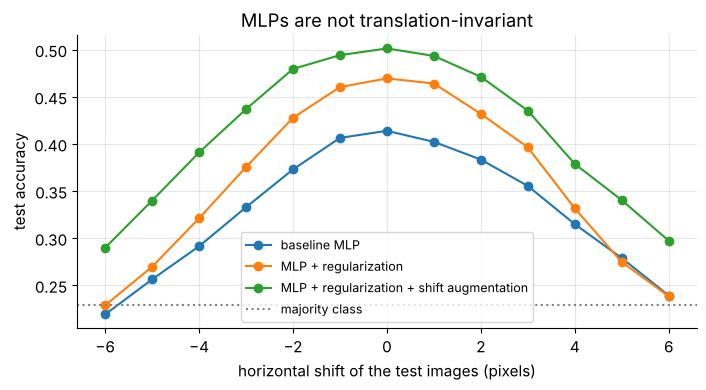

baseline MLP                                  shift 0: 0.414 | shift 2: 0.383 | shift 4: 0.315 | shift 6: 0.239
MLP + regularization                          shift 0: 0.469 | shift 2: 0.432 | shift 4: 0.332 | shift 6: 0.238
MLP + regularization + shift augmentation     shift 0: 0.501 | shift 2: 0.471 | shift 4: 0.379 | shift 6: 0.297


In [56]:
shifts = list(range(-6, 7))


def accuracy_under_shift(model: nn.Module, shifts: list[int]) -> list[float]:
    """Test accuracy after shifting all test images horizontally by each d in shifts."""
    return [(predict_logits(model, translate(X_te, d, 0)).argmax(1) == Y_te).float().mean().item() for d in shifts]


shift_curves = {"baseline MLP": accuracy_under_shift(baseline, shifts),
                "MLP + regularization": accuracy_under_shift(mlp_reg, shifts),
                "MLP + regularization + shift augmentation": accuracy_under_shift(mlp_aug, shifts)}
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, accs in shift_curves.items():
    ax.plot(shifts, accs, "o-", label=name)
ax.axhline(counts_te.max() / counts_te.sum(), color="gray", ls=":", label="majority class")
ax.set_xlabel("horizontal shift of the test images (pixels)"); ax.set_ylabel("test accuracy")
ax.set_title("MLPs are not translation-invariant"); ax.legend(fontsize=9); plt.show()
for name, accs in shift_curves.items():
    print(f"{name:45s} shift 0: {accs[6]:.3f} | shift 2: {accs[8]:.3f} | shift 4: {accs[10]:.3f} | shift 6: {accs[12]:.3f}")

Accuracy falls steadily as the faces move. The reason is structural: weight $W_{1}[u, j]$ connects hidden unit $u$
to **one fixed pixel position** $j$. If the mouth moves 4 pixels, completely different weights see it, and those
weights were trained to look at cheek or chin pixels. Augmentation helps because it shows the network shifted copies, so it
learns separate weights for each position, but that is memorization of positions, paid for with data and capacity,
not real invariance, and it only covers the range of shifts seen in training.

> **Key idea.** An MLP treats "the same pattern at a different position" as a *different* input. Convolutional
> networks build the opposite assumption into their architecture: the same small filter is applied at every position
> (weight sharing), so a pattern is detected wherever it appears.

### 10.2 The MLP does not know which pixels are neighbors

Here is a surprising experiment. Choose one fixed random permutation $\pi$ of the 2,304 pixel positions and scramble
**every** image (train, validation and test) with it. To a human the images become pure noise. For an MLP nothing
essential changes: permuting the inputs of the first layer is the same as permuting the columns of $\mathbf{W}_1$,
$\mathbf{W}_1 P_\pi \mathbf{x}$, and a randomly initialized $\mathbf{W}_1$ with permuted columns is just another random
initialization. So training on scrambled images is the same learning problem in disguise.

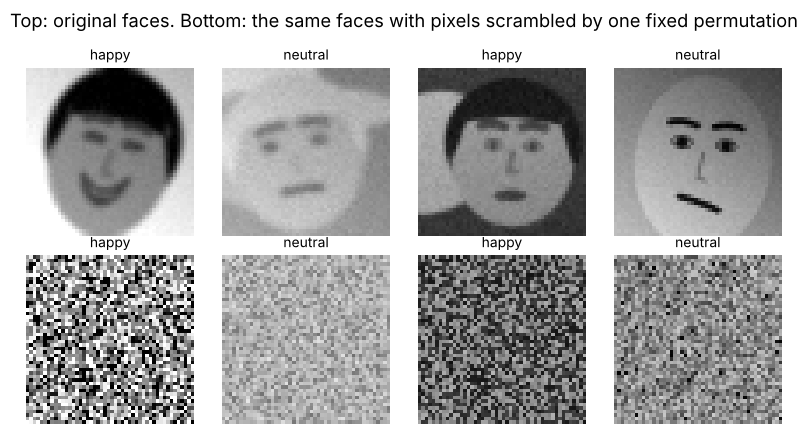

  [Adam on scrambled pixels] epoch  15 | train loss 0.983 acc 0.644 | val loss 1.580 acc 0.452 |   6.0 s
test accuracy after 15 epochs of Adam: original pixels 0.463 | scrambled pixels 0.461


In [57]:
perm = torch.from_numpy(np.random.default_rng(0).permutation(48 * 48))
scramble = lambda X: X.flatten(1)[:, perm].reshape(-1, 1, 48, 48)
show_grid(torch.cat([X_tr[:4], scramble(X_tr[:4])]), [idx2label[int(k)] for k in Y_tr[:4]] * 2, 2, 4,
          figsize=(8, 4.4), suptitle="Top: original faces. Bottom: the same faces with pixels scrambled by one fixed permutation")

torch.manual_seed(SEED)
mlp_scrambled = make_mlp().to(DEVICE)
hist_scr = fit(mlp_scrambled, torch.optim.Adam(mlp_scrambled.parameters(), lr=1e-3), epochs=15, print_every=15,
               name="Adam on scrambled pixels", data=(scramble(X_tr), Y_tr, scramble(X_va), Y_va))
acc_scr = (predict_logits(mlp_scrambled, scramble(X_te)).argmax(1) == Y_te).float().mean().item()
acc_orig = (predict_logits(mlp_adam, X_te).argmax(1) == Y_te).float().mean().item()
print(f"test accuracy after 15 epochs of Adam: original pixels {acc_orig:.3f} | scrambled pixels {acc_scr:.3f}")

The two accuracies are essentially the same (differences of a percentage point or so are ordinary seed-to-seed noise).
This is the cleanest demonstration that a pixel MLP **ignores the 2-D structure** of the image: it would be equally
happy with any fixed shuffling of the pixels. A convolutional network, which relies on neighboring pixels forming
edges and shapes, would be badly hurt by the scrambling. Real images have strong local structure, and an architecture
that does not exploit it wastes data.

### 10.3 What did the first layer learn? Weights as 48×48 templates

Each hidden unit $u$ of the first layer computes $\mathbf{w}_u^\top\mathbf{x} + b_u$, a dot product between the image and a
weight vector $\mathbf{w}_u \in \mathbb{R}^{2304}$. Reshaped to 48×48, $\mathbf{w}_u$ is a **template**: the unit fires
strongly for images that are bright where the template is positive (red) and dark where it is negative (blue).
We show the 16 units with the largest weight norms of the regularized MLP.

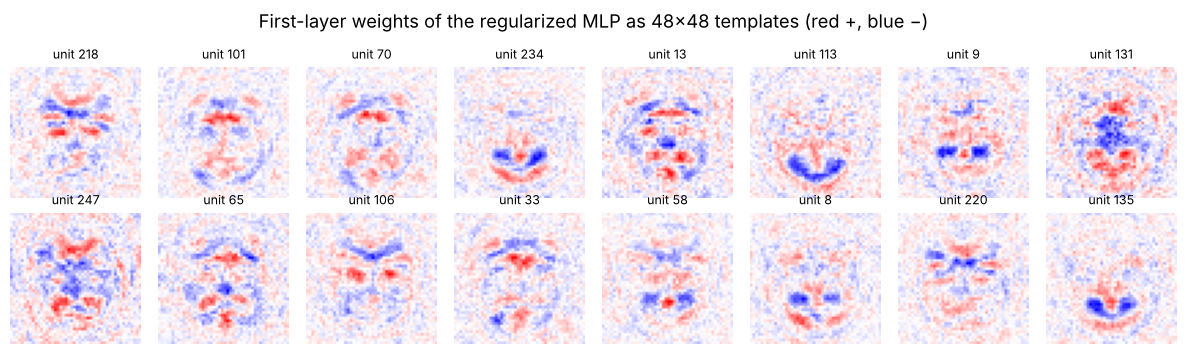

In [58]:
W1 = mlp_reg[1].weight.detach().cpu()                       # (256, 2304): layer 0 is Flatten, layer 1 the first Linear
top = W1.norm(dim=1).argsort(descending=True)[:16]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for ax, u in zip(axes.ravel(), top):
    t = W1[u].reshape(48, 48)
    lim = float(t.abs().max())
    ax.imshow(t.numpy(), cmap="bwr", vmin=-lim, vmax=lim)
    ax.set_title(f"unit {int(u)}", fontsize=9); ax.axis("off")
fig.suptitle("First-layer weights of the regularized MLP as 48×48 templates (red +, blue −)")
plt.tight_layout(); plt.show()

You should recognize face parts in many templates: blobs at the mouth position (open versus closed mouth), bars
around the eyes and brows, and contrasts between the two halves of the face. Many templates also look noisy:
with only about 7.7k SynthFaces-7 training images and 590k first-layer weights, a lot of each template is fitted
noise, which is one more symptom of the MLP's poor match to image data. Each template is tied to fixed positions,
which is exactly why the shift experiment in 10.1 hurt.

**Quick check.** Would horizontal-flip augmentation make the learned templates more left-right symmetric? Why?

<details>
<summary>Answer</summary>

Largely, yes. With flips, every training image also appears mirrored with the same label, so a template and its
mirror image receive equal "evidence". Nothing forces an individual unit to be symmetric (two units can be mirror
images of each other), but the network as a whole becomes approximately flip-invariant.
</details>

## 11. Teaser: a small convolutional network

A **convolutional layer** slides a small filter (for example 3×3) over the image. At every position $(r, c)$ it
computes the same weighted sum of the neighborhood,

$$
y[r, c] = b + \sum_{i=-1}^{1}\sum_{j=-1}^{1} w[i, j]\; x[r+i, c+j],
$$

so one filter has only $9$ weights (+1 bias) no matter how large the image is, and it detects its pattern
(an edge, a corner, a dark blob) **wherever** it occurs. This *weight sharing* is exactly what the MLP lacked in
Section 10. With **stride 2** the filter jumps two pixels at a time, which halves the resolution, and stacking such
layers lets later filters see larger and larger regions of the face. In the network below, a unit of the first layer
sees 5×5 input pixels, a unit of the second layer $5 + 2 \cdot 2 = 9$ (its 3 positions are 2 input pixels apart), and a
unit of the third layer $9 + 2 \cdot 4 = 17$, enough to cover a whole mouth or an eye with its eyebrow. Our network:

```
input 1x48x48
 -> Conv 5x5, 16 filters, stride 2 -> BatchNorm -> ReLU   -> 16x24x24
 -> Conv 3x3, 32 filters, stride 2 -> BatchNorm -> ReLU   -> 32x12x12
 -> Conv 3x3, 32 filters, stride 2 -> BatchNorm -> ReLU   -> 32x6x6
 -> Flatten (1152 numbers) -> Dropout(0.3) -> Linear(1152, 7) -> logits
```

The final `Linear` layer still has position-specific weights, but only on a coarse 6×6 grid of *local feature
detectors* instead of 2,304 raw pixels. (Replacing `Flatten` by *global average pooling* would make the network
almost fully shift-invariant, and that variant learns more slowly. *Dive into Deep Learning*, linked in Going further,
explains pooling in its convolutional-networks chapter and global average pooling in its "Network in Network" section.)

In [59]:
def make_cnn() -> nn.Sequential:
    def block(c_in, c_out, k):
        return [nn.Conv2d(c_in, c_out, kernel_size=k, stride=2, padding=k // 2), nn.BatchNorm2d(c_out), nn.ReLU()]
    return nn.Sequential(*block(1, 16, 5), *block(16, 32, 3), *block(32, 32, 3),
                         nn.Flatten(), nn.Dropout(0.3), nn.Linear(32 * 6 * 6, NUM_CLASSES))


torch.manual_seed(SEED)
cnn = make_cnn().to(DEVICE)
print(f"CNN parameters: {count_params(cnn):,}  vs  pyramid MLP: {count_params(baseline):,} "
      f"({count_params(baseline) / count_params(cnn):.0f}x more)")
cnn.eval()                                    # eval mode: this shape check must not touch BatchNorm statistics
with torch.no_grad():
    x = X_tr[:2]
    for layer in cnn:
        x = layer(x)
        if isinstance(layer, (nn.ReLU, nn.Flatten, nn.Linear)):
            print(f"  after {layer.__class__.__name__:8s} -> {tuple(x.shape)}")

CNN parameters: 22,535  vs  pyramid MLP: 631,687 (28x more)
  after ReLU     -> (2, 16, 24, 24)
  after ReLU     -> (2, 32, 12, 12)
  after ReLU     -> (2, 32, 6, 6)
  after Flatten  -> (2, 1152)
  after Linear   -> (2, 7)


We train it for only 6 epochs with Adam, the same flip/shift augmentation as the best MLP, and a smaller batch
size (128).

  [small CNN] epoch   2 | train loss 1.510 acc 0.422 | val loss 1.311 acc 0.509 |   6.2 s


  [small CNN] epoch   4 | train loss 1.201 acc 0.569 | val loss 1.168 acc 0.583 |  12.5 s


  [small CNN] epoch   6 | train loss 1.096 acc 0.611 | val loss 1.028 acc 0.635 |  18.6 s


,accuracy,balanced acc,macro-F1,disgust recall,parameters
model,,,,,
best MLP (regularized + augmentation),0.501,0.429,0.424,0.000,632583
small CNN (6 epochs),0.643,0.569,0.565,0.081,22535


MLP + regularization + shift augmentation     shift 0: 0.501 | shift +2: 0.471 | shift +4: 0.379 | shift +6: 0.297
small CNN (6 epochs)                          shift 0: 0.643 | shift +2: 0.630 | shift +4: 0.567 | shift +6: 0.459


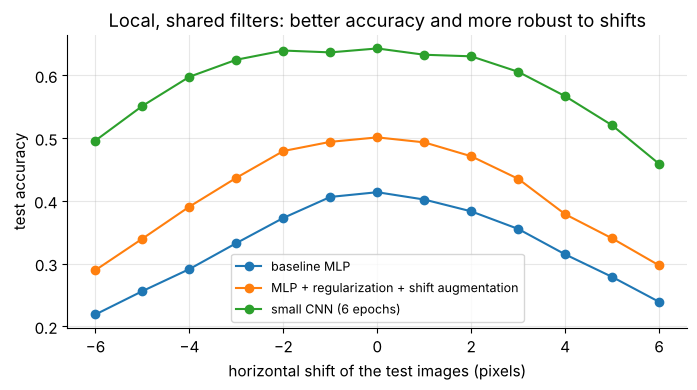

In [60]:
hist_cnn = fit(cnn, torch.optim.Adam(cnn.parameters(), lr=2e-3), epochs=6, batch_size=128, augment=augment_batch,
               print_every=2, name="small CNN")
cnn_report = test_report(cnn, "small CNN (6 epochs)")
mlp_report = test_report(mlp_aug, "best MLP (regularized + augmentation)")
cnn_table = pd.DataFrame([mlp_report, cnn_report]).set_index("model")
cnn_table["parameters"] = [count_params(mlp_aug), count_params(cnn)]
display(cnn_table.round(3))
shift_curves["small CNN (6 epochs)"] = accuracy_under_shift(cnn, shifts)
for name in ("MLP + regularization + shift augmentation", "small CNN (6 epochs)"):
    a = shift_curves[name]
    print(f"{name:45s} shift 0: {a[6]:.3f} | shift +2: {a[8]:.3f} | shift +4: {a[10]:.3f} | shift +6: {a[12]:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
for name in ("baseline MLP", "MLP + regularization + shift augmentation", "small CNN (6 epochs)"):
    ax.plot(shifts, shift_curves[name], "o-", label=name)
ax.set_xlabel("horizontal shift of the test images (pixels)"); ax.set_ylabel("test accuracy")
ax.set_title("Local, shared filters: better accuracy and more robust to shifts"); ax.legend(fontsize=9); plt.show()

With 28 times fewer parameters and only 6 epochs, the small CNN beats every MLP variant by a wide margin, and it keeps
that lead at every shift: even with the faces moved by 6 pixels it scores higher than the baseline MLP does on centered
faces. It is not perfectly shift-invariant, though. Its last layer still reads a position-specific 6×6 grid of
features, so large shifts do hurt, and global average pooling (mentioned above) removes most of that remaining sensitivity.

On the real FER-2013 the picture is the same, only with lower numbers: pixel MLPs plateau around 40–45% test accuracy,
while modest CNNs reach 60–70% and carefully engineered deep CNNs about 73%. The convolutional-networks chapter of
*Dive into Deep Learning* (Going further) explains *why* in detail: local receptive fields, weight sharing and pooling
are the right **inductive biases** (built-in assumptions) for images.

## 12. Is "emotion recognition" valid? Ethics and limits

Everything above treated the task as a technical puzzle: map pixels to one of seven labels. Before such a system
touches real people, a harder question comes first: **what does the label actually measure?**

**1. An expression is not an emotion.** The models classify *facial configurations* (raised brows, lowered mouth
corners). Whether the person *feels* surprise or sadness is a different matter. People smile when they are nervous
or polite, frown when they concentrate, and often feel strong emotions with a neutral face. A large review of the
scientific evidence (Barrett et al., 2019) concluded that facial movements are far less reliable and specific signals of
inner emotional states than the "seven basic expressions" picture suggests, and that context matters enormously.

**2. Posed versus spontaneous.** Many datasets contain posed or exaggerated expressions (actors, stock photos,
web images selected *because* they matched an emotion keyword). Spontaneous everyday expressions are subtler and
more ambiguous, so accuracy measured on posed data overestimates real-world performance.

**3. Labels are opinions.** In FER-2013, labels came from web-search keywords and a quick review, and human accuracy is
only about 65%. A model trained on such labels learns the *annotators'* judgments, including their disagreements and
biases. Our SynthFaces-7 simulated this with swapped labels, and in real data, nobody knows which labels are the wrong ones.

**4. Culture and context.** How strongly and when people show emotions ("display rules") differs between cultures,
communities, situations and individuals. A model calibrated on one population can systematically misread another.

**5. Bias across groups.** Face datasets are rarely balanced across age, skin tone, gender presentation, disability
or facial differences, and image quality varies with lighting and camera. Studies of commercial face-analysis systems
found markedly different error rates across demographic groups. Always report metrics **per group**, the same way we
reported metrics per class.

**6. Consent, privacy and misuse.** Faces are biometric data. Scraped web photos were not collected with consent for
this use. Emotion inference has been proposed for job interviews, classroom monitoring, lie detection, policing and
advertising, and in each case a wrong or biased "reading" of someone's face can affect their opportunities or freedom,
and the person often cannot contest it. Several jurisdictions now restrict such uses. For example, the European
Union's AI Act prohibits emotion recognition in workplaces and educational institutions, except for medical or
safety reasons.

**Questions to ask before building or deploying such a system**

| Question | Why it matters |
|---|---|
| What exactly is being predicted: a facial movement, a self-reported feeling, an annotator's opinion? | Determines whether the claims made about the system are valid at all |
| Were the data collected with consent, and from people like the intended users? | Legality, and distribution shift between training data and use |
| How do errors differ across groups (age, skin tone, gender, disability)? | Unequal error rates mean unequal treatment |
| What happens to a person when the model is wrong, and can they contest it? | High-stakes decisions need human review and an appeal path |
| Is there a less invasive way to get the same information (for example, simply asking people)? | Proportionality |

> **Key idea.** High accuracy on a benchmark shows that a model reproduces the benchmark's labels. It does not show that
> the labels measure what you care about, or that using the model is fair, legal or wise.

## 13. Quiz

Ten exam-style questions. Decide on an answer *before* opening the explanation.

**Q1.** A grayscale batch from a `DataLoader` has shape `(64, 1, 48, 48)` and goes through `nn.Flatten()` into the first
`nn.Linear` layer. What must `in_features` be?
(A) 48  (B) 2304  (C) 147456  (D) 3072

<details>
<summary>Answer</summary>

**(B)**. `nn.Flatten()` keeps the batch dimension and merges the rest: $1 \cdot 48 \cdot 48 = 2304$.
(A) is the length of a single row. (C) $= 64 \cdot 2304$ is what you get if the batch dimension is flattened too, the
`x.view(-1)` bug. (D) $= 3 \cdot 32 \cdot 32$ belongs to small color images, not to this batch.
</details>

**Q2.** The training script builds `label2idx` from `os.listdir(train_dir)` on one computer, and the evaluation script builds it
from `os.listdir(test_dir)` on another. What is the most likely symptom of this bug?
(A) A `KeyError` crash. (B) Nothing, because the mapping is always alphabetical. (C) No error message, but some classes look
systematically "confused" and the reported metrics are wrong. (D) The `DataLoader` refuses to shuffle.

<details>
<summary>Answer</summary>

**(C)**. Both mappings contain the same keys, so nothing crashes (not A), but if the listing orders differ, the same
class gets different integers in the two scripts and correct predictions are reported as errors. (B) is false: the
listing order depends on the file system. (D) has nothing to do with label maps. The fix is `sorted(...)`.
</details>

**Q3.** You upsample 48×48 images to 96×96 (bilinear) before an MLP whose first layer has 512 units. Which statement is true?
(A) The images gain detail, so validation accuracy must improve. (B) The network can represent exactly the same
functions as with 48×48 input, but its first layer has 4 times as many weights. (C) The network loses the ability to
represent some functions. (D) Upsampling makes the MLP translation-invariant.

<details>
<summary>Answer</summary>

**(B)**. Upsampling is a fixed linear map $U$ with full column rank, so $\mathbf{W}'U$ can be any matrix: same function
class, while the first layer grows from $2304 \cdot 512$ to $9216 \cdot 512$ weights. (A) interpolation creates no new
information. (C) is false because $U$ loses nothing. (D) resizing does not change how weights are tied to positions.
</details>

**Q4.** A training set has 900 images of class A, 90 of B and 10 of C. What are the inverse-frequency weights $w_k = N/(K n_k)$?
(A) $(0.370, 3.704, 33.33)$  (B) $(0.9, 0.09, 0.01)$  (C) $(1, 10, 100)$  (D) $(1/3, 1/3, 1/3)$

<details>
<summary>Answer</summary>

**(A)**: $1000/(3 \cdot 900) = 0.370$, $1000/(3 \cdot 90) = 3.704$, $1000/(3 \cdot 10) = 33.33$. (B) are the class
frequencies, which would make the imbalance *worse*. (C) has the wrong ratios (1 : 10 : 100 instead of 1 : 10 : 90). (D)
weights all classes equally, i.e. the unweighted loss. Note that any positive multiple of (A) trains identically,
because PyTorch divides by the sum of the weights.
</details>

**Q5.** A test set has 990 images of class 0 and 10 of class 1, and a model predicts class 0 for every image. Its accuracy,
balanced accuracy and macro-F1 are approximately:
(A) 0.99, 0.99, 0.99  (B) 0.99, 0.50, 0.50  (C) 0.50, 0.50, 0.50  (D) 0.99, 0.50, 0.99

<details>
<summary>Answer</summary>

**(B)**. Accuracy $= 990/1000$. Recalls are 1 and 0, so balanced accuracy $= 0.5$. Class 0 has precision 0.99 and recall
1, so $F_1 \approx 0.995$, class 1 has $F_1 = 0$, and macro-F1 $\approx 0.497$. (A) and (D) trust accuracy-like averages that
ignore the missed class, and (C) gets accuracy wrong.
</details>

**Q6.** Why does scrambling the pixels of *every* image with one fixed permutation hardly change an MLP's accuracy?
(A) The random permutation averages out over a batch. (B) Permuting the inputs is equivalent to permuting the columns of
$\mathbf{W}_1$, so the learning problem is the same in disguise. (C) MLPs are translation-invariant. (D) The permutation
keeps each image's mean brightness.

<details>
<summary>Answer</summary>

**(B)**. $\mathbf{W}_1 P\mathbf{x} = (\mathbf{W}_1P)\mathbf{x}$, and a randomly initialized $\mathbf{W}_1$ with permuted columns is
just another random initialization. (A) nothing is averaged: the same permutation is applied everywhere. (C) is false
(Section 10.1). (D) is true but irrelevant: the permutation preserves *every* pixel value, and the mean alone could not
explain the accuracy.
</details>

**Q7.** You forget `model.eval()` before validating a network with `Dropout(0.5)` and `BatchNorm1d`, but you do use
`torch.no_grad()`. What happens?
(A) Validation results become random and usually worse, and BatchNorm's running statistics are updated with validation
batches. (B) Nothing, because `torch.no_grad()` also switches Dropout off. (C) The validation loss is exactly zero.
(D) PyTorch raises an error.

<details>
<summary>Answer</summary>

**(A)**. In training mode Dropout keeps zeroing units and BatchNorm uses batch statistics (and updates its running
averages). (B) is a common misconception: `no_grad` only stops gradient tracking and does not change layer behavior.
(C) and (D) do not happen: the bug is silent.
</details>

**Q8.** An MLP reaches 42% test accuracy on centered faces but only 30% when the test faces are shifted by 4 pixels. Which
change addresses the *cause* most directly?
(A) Double the width of the first layer. (B) Train with random-shift augmentation, or better, use a convolutional network
with pooling. (C) Raise the learning rate. (D) Upsample the images to 128×128.

<details>
<summary>Answer</summary>

**(B)**. The cause is that each weight is tied to a fixed pixel position. Shift augmentation teaches the MLP shifted
positions explicitly, and convolution with weight sharing and pooling builds the invariance into the architecture. (A) adds
capacity but no invariance, (C) is unrelated, and (D) changes nothing about position dependence (Q3).
</details>

**Q9.** For the first 8 epochs, the training loss of an MLP stays at about 1.82 and its validation accuracy equals the share of
the largest class. The entropy of the training labels is 1.819 nats. What is going on?
(A) The learning rate is too high and training diverged. (B) The model ignores the image and predicts the class
frequencies (learned through the output biases), and the loss of that solution is exactly the label entropy.
(C) All labels are wrong. (D) The model is overfitting.

<details>
<summary>Answer</summary>

**(B)**. If $p_k$ are the class frequencies, predicting them for every image gives an average cross-entropy of
$-\sum_k p_k \log p_k$, the entropy. Escaping this plateau requires features of the image, which take longer to learn
with plain SGD and small initial weights. (A) divergence would make the loss grow or become `nan`. (C) wrong labels would
not produce exactly the entropy. (D) overfitting means training loss *below* validation loss, not a flat plateau.
</details>

**Q10.** A company plans to rate job applicants' "enthusiasm" from interview videos with an expression classifier that has 70%
benchmark accuracy. Which objection is the most fundamental?
(A) 70% is below the state of the art, and a bigger model would fix it. (B) The model predicts facial configurations as
judged by annotators, not enthusiasm, and its errors may differ between groups. Applicants cannot contest the score, and
such uses are legally restricted in some places. (C) Interview videos are in color but the model expects grayscale.
(D) The model may be too slow for real time.

<details>
<summary>Answer</summary>

**(B)**. The problem is *validity and fairness*, not engineering: even a perfect expression classifier would not measure
enthusiasm. (A), (C) and (D) are fixable technical details that leave the fundamental issue untouched.
</details>

## 14. Summary and going further

| Topic | Key facts and formulas |
|---|---|
| Image tensors | NumPy/OpenCV: `H×W(×C)`, PyTorch: `C×H×W`, batches `N×C×H×W`, files store `uint8` in 0–255 |
| Normalization | convert to `float32`, $x/127.5 - 1 \in [-1, 1]$, statistics from the training split only |
| Flattening | row-major, pixel $(r, c) \to r W + c$, and `nn.Flatten()` keeps the batch dimension |
| Labels | `label2idx` from **sorted** folder names, and never trust `os.listdir` order |
| Splits | stratified train/validation split, and touch the test set once, at the end |
| Data pipeline | `Dataset` (`__len__`, `__getitem__`) + `DataLoader` (batching, shuffling), preload small datasets |
| Resolution | upsampling is a fixed linear map: same function class, 6.7× more MLP parameters at 128×128 |
| Pyramid MLP | 2304 → 256 → 128 → 64 → 7, 631,687 parameters (93% in the first layer), raw logits + `CrossEntropyLoss` |
| Imbalance | confusion matrix, precision $C_{kk}/\text{col}_k$, recall $C_{kk}/\text{row}_k$, balanced accuracy, macro-F1, weights $w_k = N/(K n_k)$ |
| Training | SGD + momentum or Adam(W), BatchNorm, Dropout, weight decay, early stopping on validation loss, `train()`/`eval()` modes |
| MLP limits | not translation-invariant, blind to pixel order (scrambling-invariant), first-layer weights are position-bound templates |
| CNN teaser | local filters with weight sharing: 28× fewer parameters, higher accuracy, far more robust to shifts |
| Ethics | expressions ≠ emotions, posed vs spontaneous, label noise, cultural and demographic bias, consent, restricted uses |

**What to expect when you run this notebook on the real FER-2013.** Exactly the same code runs if `data/fer2013/`
exists (Section 1.2). Expect roughly 40–45% test accuracy for the MLP variants and 60–70% for small CNNs trained longer.
For comparison, a carefully tuned VGG-style network reaches about 73% (Khaireddin and Chen, 2021), later single models
report up to about 76%, and humans agree with the labels about 65% of the time. "Disgust" is about 1.5% of the
training data, so watch its recall. Training takes about 3–4 times longer because the dataset is 3 times larger.

**Going further**

- I. Goodfellow et al. (2013), [Challenges in Representation Learning: A report on three machine learning contests](https://arxiv.org/abs/1307.0414), the paper that introduced FER-2013 and the human-accuracy estimate.
- Y. Khaireddin and Z. Chen (2021), [Facial Emotion Recognition: State of the Art Performance on FER2013](https://arxiv.org/abs/2105.03588), a carefully tuned VGG-style network (73.28% test accuracy).
- L. F. Barrett et al. (2019), [Emotional Expressions Reconsidered: Challenges to Inferring Emotion From Human Facial Movements](https://journals.sagepub.com/doi/10.1177/1529100619832930), the scientific review behind Section 12.
- J. Byrd and Z. Lipton (2019), [What is the Effect of Importance Weighting in Deep Learning?](https://proceedings.mlr.press/v97/byrd19a.html), why class weights fade once a network can fit its training data (Section 8).
- J. Buolamwini and T. Gebru (2018), [Gender Shades: Intersectional Accuracy Disparities in Commercial Gender Classification](https://proceedings.mlr.press/v81/buolamwini18a.html), how to audit face-analysis systems per group.
- PyTorch tutorial: [Datasets & DataLoaders](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html) and the [`CrossEntropyLoss` documentation](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) (see the `weight` argument).
- S. Ioffe and C. Szegedy (2015), [Batch Normalization](https://arxiv.org/abs/1502.03167). N. Srivastava et al. (2014), [Dropout](https://jmlr.org/papers/v15/srivastava14a.html). I. Loshchilov and F. Hutter (2019), [Decoupled Weight Decay Regularization (AdamW)](https://arxiv.org/abs/1711.05101).
- A. Zhang et al., *Dive into Deep Learning*, [chapter on convolutional neural networks](https://d2l.ai/chapter_convolutional-neural-networks/index.html), the natural next step after this notebook, and global average pooling appears in the [Network in Network](https://d2l.ai/chapter_convolutional-modern/nin.html) section of the chapter that follows.
- The dataset on Kaggle: [FER-2013 (folder version)](https://www.kaggle.com/datasets/msambare/fer2013).